# Deep Learning Lab Assignment: CNN Feature Visualization, Parameter Audit and Critical Analysis

| Field | Student Information |
|---|---|
| **Student Name** | Muhammad Sayyam |
| **Roll No.** | FA23-BAI-030 |
| **Course / Section** | Computer Vision |
| **Submission Date** | 26/Nov/2026 |

Framework: TensorFlow / Keras (convolution, ReLU and pooling are run with `tf.nn` ops so every stage is a real tensor output), NumPy, OpenCV and Matplotlib.

Notebook layout:

1. Setup and input image
2. Part I: five 3x3 kernels, four stages (A to D), 5 x 4 grid
3. Part II: Model A and Model B, hand calculation, `model.summary()` check, audit table
4. Supporting experiments for Questions 1 to 5 (the written answers are in the separate answers document)

## 0. Setup

In [ ]:
import os, io, time, random
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
np.random.seed(SEED); random.seed(SEED); tf.random.set_seed(SEED)
pd.set_option("display.precision", 4)
print("TensorFlow", tf.__version__, "| OpenCV", cv2.__version__, "| NumPy", np.__version__)

TensorFlow 2.21.0 | OpenCV 5.0.0 | NumPy 2.5.3


## 1. Input image

The assignment asks for an image with clear horizontal and vertical edges, texture and contrast gradients (like the building in Figure 2). To keep the notebook fully reproducible offline, it builds a 256 x 256 grayscale building facade:

* **Sky** (rows 0 to 59 and the sides): a smooth gradient that gets slightly darker from top to bottom.
* **Roof line** at row 60: bright sky above, mid-gray wall below.
* **Wall**: gray value 0.55 with light random texture.
* **Windows**: a 4 x 5 grid of dark panes, each split by a 1-pixel-wide bright mullion (one vertical, one horizontal).
* **Door**: dark rectangle at the bottom centre.
* **Ground**: brick pattern with bright mortar lines.

To use your own photo instead, set `IMAGE_PATH` to the file path. Pixel values are scaled to [0, 1], which is the usual CNN input range.

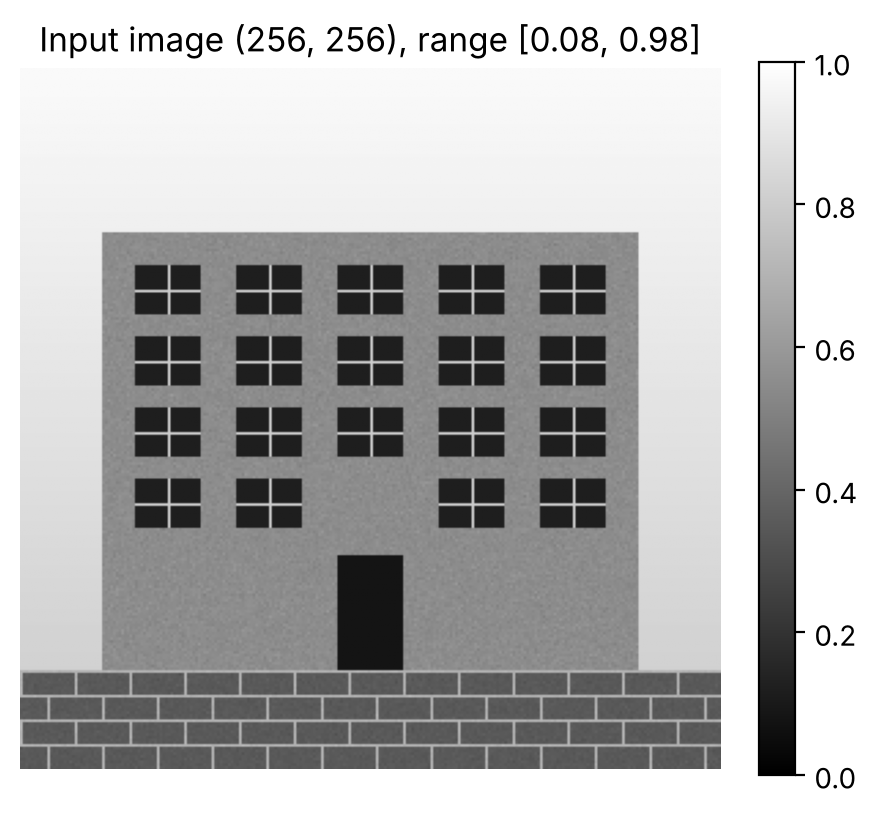

In [ ]:
IMAGE_PATH = None   # e.g. "my_building.jpg"

def make_building(size=256, seed=SEED):
    rng = np.random.default_rng(seed)
    H = W = size
    img = np.zeros((H, W), np.float32)
    # sky gradient: 0.98 at the top down to 0.82 at the ground line
    sky = np.linspace(0.98, 0.82, 220, dtype=np.float32)[:, None]
    img[:220, :] = sky
    # wall with texture
    img[60:220, 30:226] = 0.55 + rng.normal(0, 0.015, (160, 196)).astype(np.float32)
    # windows 4 rows x 5 cols
    for r in range(4):
        for c in range(5):
            y0, x0 = 72 + r * 26, 42 + c * 37
            if r == 3 and c == 2:      # leave room for the door
                continue
            img[y0:y0 + 18, x0:x0 + 24] = 0.12
            img[y0:y0 + 18, x0 + 12] = 0.80      # vertical mullion, 1 px
            img[y0 + 9, x0:x0 + 24] = 0.80       # horizontal mullion, 1 px
    # door
    img[178:220, 116:140] = 0.08
    # ground: bricks
    g = np.full((36, W), 0.35, np.float32)
    for i in range(36):
        if i % 9 == 0:
            g[i, :] = 0.70
        else:
            off = 0 if (i // 9) % 2 == 0 else 10
            g[i, off::20] = 0.70
    img[220:, :] = g + rng.normal(0, 0.01, g.shape).astype(np.float32)
    return np.clip(img, 0, 1)

if IMAGE_PATH:
    raw = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(raw, (256, 256), interpolation=cv2.INTER_AREA).astype(np.float32) / 255.0
else:
    img = make_building()

plt.figure(figsize=(5, 5))
plt.imshow(img, cmap="gray", vmin=0, vmax=1)
plt.title(f"Input image {img.shape}, range [{img.min():.2f}, {img.max():.2f}]")
plt.colorbar(fraction=0.046)
plt.axis("off"); plt.show()

# Part I: Filter Pipeline Implementation and Visualization

## 1.1 The five 3x3 kernels

A note on naming. Books disagree on what "Sobel-X" means. Here the names describe **the edge the kernel responds to**:

* **Horizontal edge detector**: differences along the vertical (y) direction, so it fires on horizontal lines such as the roof line and the top and bottom of each window. Same as the kernel usually written as Sobel-Y / G<sub>y</sub>.
* **Vertical edge detector**: differences along the horizontal (x) direction, so it fires on the left and right sides of windows, the door and the wall. Same as Sobel-X / G<sub>x</sub>.

All convolutions below are cross-correlations (no kernel flip), which is what `tf.nn.conv2d` and every CNN layer compute. So the sign of the output is read directly off the kernel: positive weights sit on the bottom row of the horizontal kernel and the right column of the vertical kernel.

In [ ]:
KERNELS = {
    "Horizontal Edge (Sobel)": np.array([[-1, -2, -1],
                                         [ 0,  0,  0],
                                         [ 1,  2,  1]], np.float32),
    "Vertical Edge (Sobel)":   np.array([[-1,  0,  1],
                                         [-2,  0,  2],
                                         [-1,  0,  1]], np.float32),
    "Sharpen":                 np.array([[ 0, -1,  0],
                                         [-1,  5, -1],
                                         [ 0, -1,  0]], np.float32),
    "Gaussian Blur":           np.array([[1, 2, 1],
                                         [2, 4, 2],
                                         [1, 2, 1]], np.float32) / 16.0,
    "Emboss":                  np.array([[-2, -1,  0],
                                         [-1,  1,  1],
                                         [ 0,  1,  2]], np.float32),
}
for name, k in KERNELS.items():
    print(f"{name}   (sum of weights = {k.sum():.2f})\n{k}\n")

Horizontal Edge (Sobel)   (sum of weights = 0.00)
[[-1. -2. -1.]
 [ 0.  0.  0.]
 [ 1.  2.  1.]]

Vertical Edge (Sobel)   (sum of weights = 0.00)
[[-1.  0.  1.]
 [-2.  0.  2.]
 [-1.  0.  1.]]

Sharpen   (sum of weights = 1.00)
[[ 0. -1.  0.]
 [-1.  5. -1.]
 [ 0. -1.  0.]]

Gaussian Blur   (sum of weights = 1.00)
[[0.0625 0.125  0.0625]
 [0.125  0.25   0.125 ]
 [0.0625 0.125  0.0625]]

Emboss   (sum of weights = 1.00)
[[-2. -1.  0.]
 [-1.  1.  1.]
 [ 0.  1.  2.]]



## 1.2 Running the four stages

For each kernel, independently:

* **Stage A**: raw convolution, `tf.nn.conv2d`, stride 1, `VALID` padding (no zero padding, so no fake edges at the image border). 256 x 256 becomes 254 x 254.
* **Stage B**: `tf.nn.relu` on Stage A.
* **Stage C**: `tf.nn.max_pool2d` on Stage B, window 2x2, stride 2. 254 x 254 becomes 127 x 127.
* **Stage D**: `tf.nn.avg_pool2d` on Stage B, window 2x2, stride 2. 127 x 127.

In [ ]:
x = tf.constant(img[None, :, :, None])          # NHWC: (1, 256, 256, 1)

def run_pipeline(x, k):
    w = tf.constant(k[:, :, None, None])        # (3, 3, in=1, out=1)
    A = tf.nn.conv2d(x, w, strides=1, padding="VALID")
    B = tf.nn.relu(A)
    C = tf.nn.max_pool2d(B, ksize=2, strides=2, padding="VALID")
    D = tf.nn.avg_pool2d(B, ksize=2, strides=2, padding="VALID")
    return {s: t.numpy()[0, :, :, 0] for s, t in zip("ABCD", (A, B, C, D))}

results = {name: run_pipeline(x, k) for name, k in KERNELS.items()}

rows = []
for name, st in results.items():
    for s in "ABCD":
        t = st[s]
        rows.append({"Filter": name, "Stage": s, "Shape": t.shape,
                     "Min": t.min(), "Max": t.max(), "Mean": t.mean(),
                     "% negative": 100 * (t < 0).mean(),
                     "% exactly zero": 100 * (t == 0).mean()})
stats = pd.DataFrame(rows)
stats

,Filter,Stage,Shape,Min,Max,Mean,% negative,% exactly zero
0,Horizontal Edge (Sobel),A,"(254, 254)",-2.72,2.7200,-0.0193,64.2011,1.3640
1,Horizontal Edge (Sobel),B,"(254, 254)",0.00,2.7200,0.0689,0.0000,65.5651
2,Horizontal Edge (Sobel),C,"(127, 127)",0.00,2.7200,0.1220,0.0000,47.2007
3,Horizontal Edge (Sobel),D,"(127, 127)",0.00,2.0591,0.0689,0.0000,47.2007
4,Vertical Edge (Sobel),A,"(254, 254)",-2.72,2.7200,-0.0004,26.3036,47.5107
5,Vertical Edge (Sobel),B,"(254, 254)",0.00,2.7200,0.0561,0.0000,73.8142
6,Vertical Edge (Sobel),C,"(127, 127)",0.00,2.7200,0.1031,0.0000,55.9365
7,Vertical Edge (Sobel),D,"(127, 127)",0.00,1.9308,0.0561,0.0000,55.9365
8,Sharpen,A,"(254, 254)",-1.24,2.4407,0.6182,6.4093,0.0000
9,Sharpen,B,"(254, 254)",0.00,2.4407,0.6418,0.0000,6.4093


## 1.3 The 5 x 4 visualization grid

Intensity scaling rule (kept the same for every row):

* **Stage A** is signed, so it is drawn on a symmetric scale [-m, +m] with m = max|A| for that row. Gray colormap: black = most negative, mid-gray = 0, white = most positive.
* **Stages B, C and D** of a row share one scale [0, max(B)]. Black = 0. Because the three panels use the same scale, a drop in brightness from C to D is a real drop in value, not a display effect.

Every panel has its own colorbar.

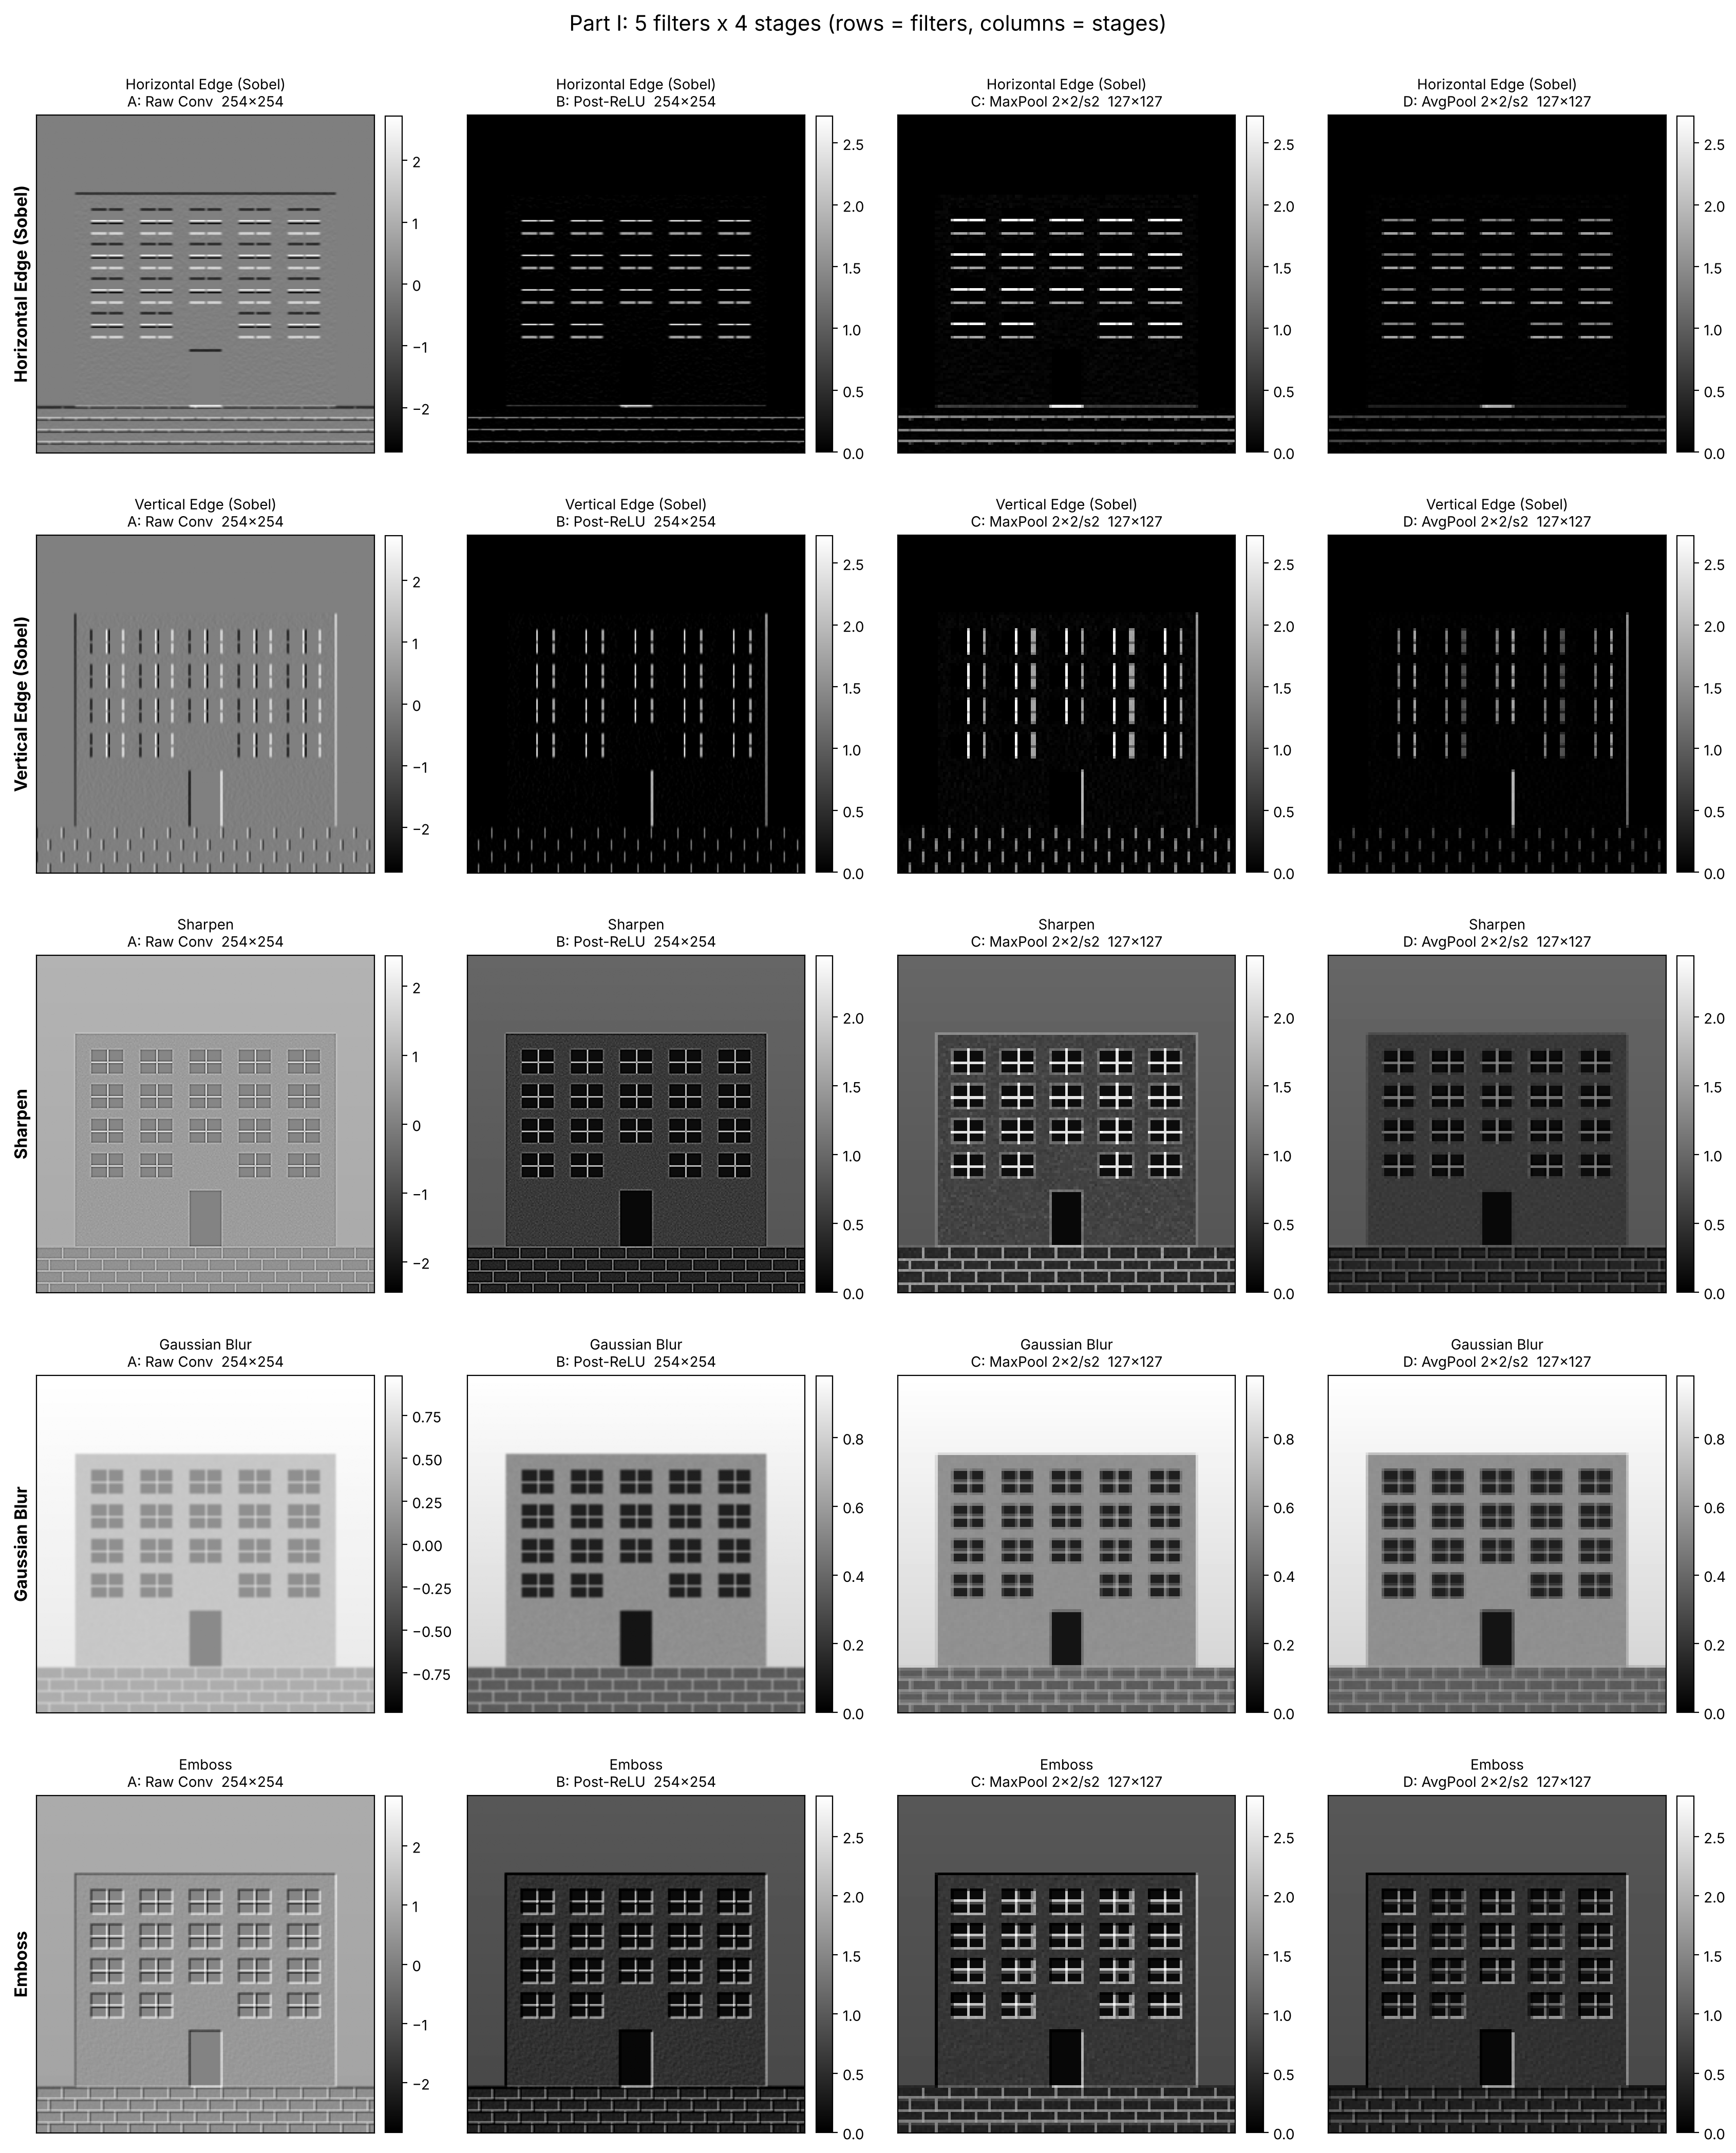

In [ ]:
STAGE_TITLES = {"A": "A: Raw Conv", "B": "B: Post-ReLU",
                "C": "C: MaxPool 2x2/s2", "D": "D: AvgPool 2x2/s2"}

fig, axes = plt.subplots(5, 4, figsize=(17, 21))
for i, (name, st) in enumerate(results.items()):
    m = np.abs(st["A"]).max()
    bmax = st["B"].max()
    for j, s in enumerate("ABCD"):
        ax = axes[i, j]
        vmin, vmax = (-m, m) if s == "A" else (0, bmax)
        im = ax.imshow(st[s], cmap="gray", vmin=vmin, vmax=vmax)
        ax.set_title(f"{name}\n{STAGE_TITLES[s]}  {st[s].shape[0]}x{st[s].shape[1]}", fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
    axes[i, 0].set_ylabel(name, fontsize=12, fontweight="bold")
fig.suptitle("Part I: 5 filters x 4 stages (rows = filters, columns = stages)", fontsize=15, y=1.0)
plt.tight_layout()
plt.savefig("part1_grid_5x4.png", dpi=130, bbox_inches="tight")
plt.show()

### Observations from the grid (used in the answers)

The table below is printed from the actual tensors, so the written answers can quote exact numbers.

In [ ]:
summary = stats.pivot_table(index="Filter", columns="Stage",
                            values=["% negative", "% exactly zero", "Max"], aggfunc="first")
summary = summary.reindex(list(KERNELS.keys()))
summary

% exactly zero                            % negative  \
Stage                                A        B        C        D          A   
Filter                                                                         
Horizontal Edge (Sobel)         1.3640  65.5651  47.2007  47.2007    64.2011   
Vertical Edge (Sobel)          47.5107  73.8142  55.9365  55.9365    26.3036   
Sharpen                         0.0000   6.4093   0.0000   0.0000     6.4093   
Gaussian Blur                   0.0000   0.0000   0.0000   0.0000     0.0000   
Emboss                          0.0000   6.6092   2.8458   2.8458     6.6092   

                                           Max                          
Stage                      B    C    D       A       B       C       D  
Filter                                                                  
Horizontal Edge (Sobel)  0.0  0.0  0.0  2.7200  2.7200  2.7200  2.0591  
Vertical Edge (Sobel)    0.0  0.0  0.0  2.7200  2.7200  2.7200  1.9308  
Sharpen                  0.0  0.0  0.0  2.4407  2.4407  2.4407  1.2800  
Gaussian Blur            0.0  0.0  0.0  0.9793  0.9793  0.9793  0.9789  
Emboss                   0.0  0.0  0.0  2.8400  2.8400  2.8400  2.0865

# Part II: Architectural Comparison and Parameter Audit

## 2.1 Hand calculation (done before building the models)

Formula: **Params per conv layer = (K<sub>h</sub> x K<sub>w</sub> x C<sub>in</sub> + 1) x C<sub>out</sub>**. The "+1" is the bias of each filter.
Pooling and Global Average Pooling have no weights. Dense layer: (inputs + 1) x outputs.

Layer order in both models: Input 32x32x3, Conv1 + ReLU, Pool, Conv2 + ReLU, Pool, GlobalAveragePooling2D, Dense(10).

**Model A (3x3 kernels, Max Pooling)**

| Layer | Working | Params |
|---|---|---|
| Conv1 | (3 x 3 x 3 + 1) x 5 = (27 + 1) x 5 = 28 x 5 | 140 |
| MaxPool 2x2 | no weights | 0 |
| Conv2 | (3 x 3 x 5 + 1) x 10 = (45 + 1) x 10 = 46 x 10 | 460 |
| MaxPool 2x2 | no weights | 0 |
| GAP | no weights, output length = 10 channels | 0 |
| Dense(10) | (10 + 1) x 10 = 11 x 10 | 110 |
| **Total** | 140 + 460 + 110 | **710** |

**Model B (5x5 kernels, Average Pooling)**

| Layer | Working | Params |
|---|---|---|
| Conv1 | (5 x 5 x 3 + 1) x 5 = (75 + 1) x 5 = 76 x 5 | 380 |
| AvgPool 2x2 | no weights | 0 |
| Conv2 | (5 x 5 x 5 + 1) x 10 = (125 + 1) x 10 = 126 x 10 | 1,260 |
| AvgPool 2x2 | no weights | 0 |
| GAP | no weights | 0 |
| Dense(10) | (10 + 1) x 10 = 11 x 10 | 110 |
| **Total** | 380 + 1,260 + 110 | **1,750** |

The pooling type (max vs average) changes nothing in the count. Padding (`valid` or `same`) also changes nothing, because weights depend only on kernel size and channels. The next cell repeats the same arithmetic in code so it can be checked against Keras.

In [ ]:
def conv_params(kh, kw, cin, cout):
    return (kh * kw * cin + 1) * cout

def dense_params(nin, nout):
    return (nin + 1) * nout

def manual_audit(k, label):
    c1 = conv_params(k, k, 3, 5)
    c2 = conv_params(k, k, 5, 10)
    d = dense_params(10, 10)
    print(f"{label}")
    print(f"  Conv1 : ({k}x{k}x3 + 1) x 5  = ({k*k*3} + 1) x 5  = {c1}")
    print(f"  Pool1 : 0")
    print(f"  Conv2 : ({k}x{k}x5 + 1) x 10 = ({k*k*5} + 1) x 10 = {c2}")
    print(f"  Pool2 : 0   GAP : 0")
    print(f"  Dense : (10 + 1) x 10 = {d}")
    print(f"  Total : {c1} + {c2} + {d} = {c1 + c2 + d}\n")
    return {"conv1": c1, "conv2": c2, "dense": d, "total": c1 + c2 + d}

manual_A = manual_audit(3, "Model A (3x3, MaxPool)")
manual_B = manual_audit(5, "Model B (5x5, AvgPool)")

Model A (3x3, MaxPool)
  Conv1 : (3x3x3 + 1) x 5  = (27 + 1) x 5  = 140
  Pool1 : 0
  Conv2 : (3x3x5 + 1) x 10 = (45 + 1) x 10 = 460
  Pool2 : 0   GAP : 0
  Dense : (10 + 1) x 10 = 110
  Total : 140 + 460 + 110 = 710

Model B (5x5, AvgPool)
  Conv1 : (5x5x3 + 1) x 5  = (75 + 1) x 5  = 380
  Pool1 : 0
  Conv2 : (5x5x5 + 1) x 10 = (125 + 1) x 10 = 1260
  Pool2 : 0   GAP : 0
  Dense : (10 + 1) x 10 = 110
  Total : 380 + 1260 + 110 = 1750



## 2.2 Building the two models in Keras

In [ ]:
def build_model(k, pool, name):
    Pool = layers.MaxPooling2D if pool == "max" else layers.AveragePooling2D
    return keras.Sequential([
        keras.Input(shape=(32, 32, 3)),
        layers.Conv2D(5, (k, k), activation="relu", name="conv1"),
        Pool(pool_size=2, strides=2, name="pool1"),
        layers.Conv2D(10, (k, k), activation="relu", name="conv2"),
        Pool(pool_size=2, strides=2, name="pool2"),
        layers.GlobalAveragePooling2D(name="gap"),
        layers.Dense(10, activation="softmax", name="output"),
    ], name=name)

model_A = build_model(3, "max", "Model_A_Standard_3x3")
model_B = build_model(5, "avg", "Model_B_LargeKernel_5x5")

summaries = {}
for m in (model_A, model_B):
    buf = []
    m.summary(print_fn=lambda s, **kw: buf.append(s), line_length=90)
    summaries[m.name] = "\n".join(buf)
    m.summary(line_length=90)

Model: "Model_A_Standard_3x3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                          ┃ Output Shape                 ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                        │ (None, 30, 30, 5)            │             140 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ pool1 (MaxPooling2D)                  │ (None, 15, 15, 5)            │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ conv2 (Conv2D)                        │ (None, 13, 13, 10)           │             460 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ pool2 (MaxPooling2D)                  │ (None, 6, 6, 10)             │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ gap (GlobalAveragePooling2D)          │ (None, 10)                   │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ output (Dense)                        │ (None, 10)                   │             110 │
└───────────────────────────────────────┴──────────────────────────────┴─────────────────┘

 Total params: 710 (2.77 KB)

 Trainable params: 710 (2.77 KB)

 Non-trainable params: 0 (0.00 B)

Model: "Model_B_LargeKernel_5x5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                          ┃ Output Shape                 ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                        │ (None, 28, 28, 5)            │             380 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ pool1 (AveragePooling2D)              │ (None, 14, 14, 5)            │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ conv2 (Conv2D)                        │ (None, 10, 10, 10)           │           1,260 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ pool2 (AveragePooling2D)              │ (None, 5, 5, 10)             │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ gap (GlobalAveragePooling2D)          │ (None, 10)                   │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ output (Dense)                        │ (None, 10)                   │             110 │
└───────────────────────────────────────┴──────────────────────────────┴─────────────────┘

 Total params: 1,750 (6.84 KB)

 Trainable params: 1,750 (6.84 KB)

 Non-trainable params: 0 (0.00 B)

Saving the two `model.summary()` outputs as PNG images (for the 'screenshot of the framework output' requirement).

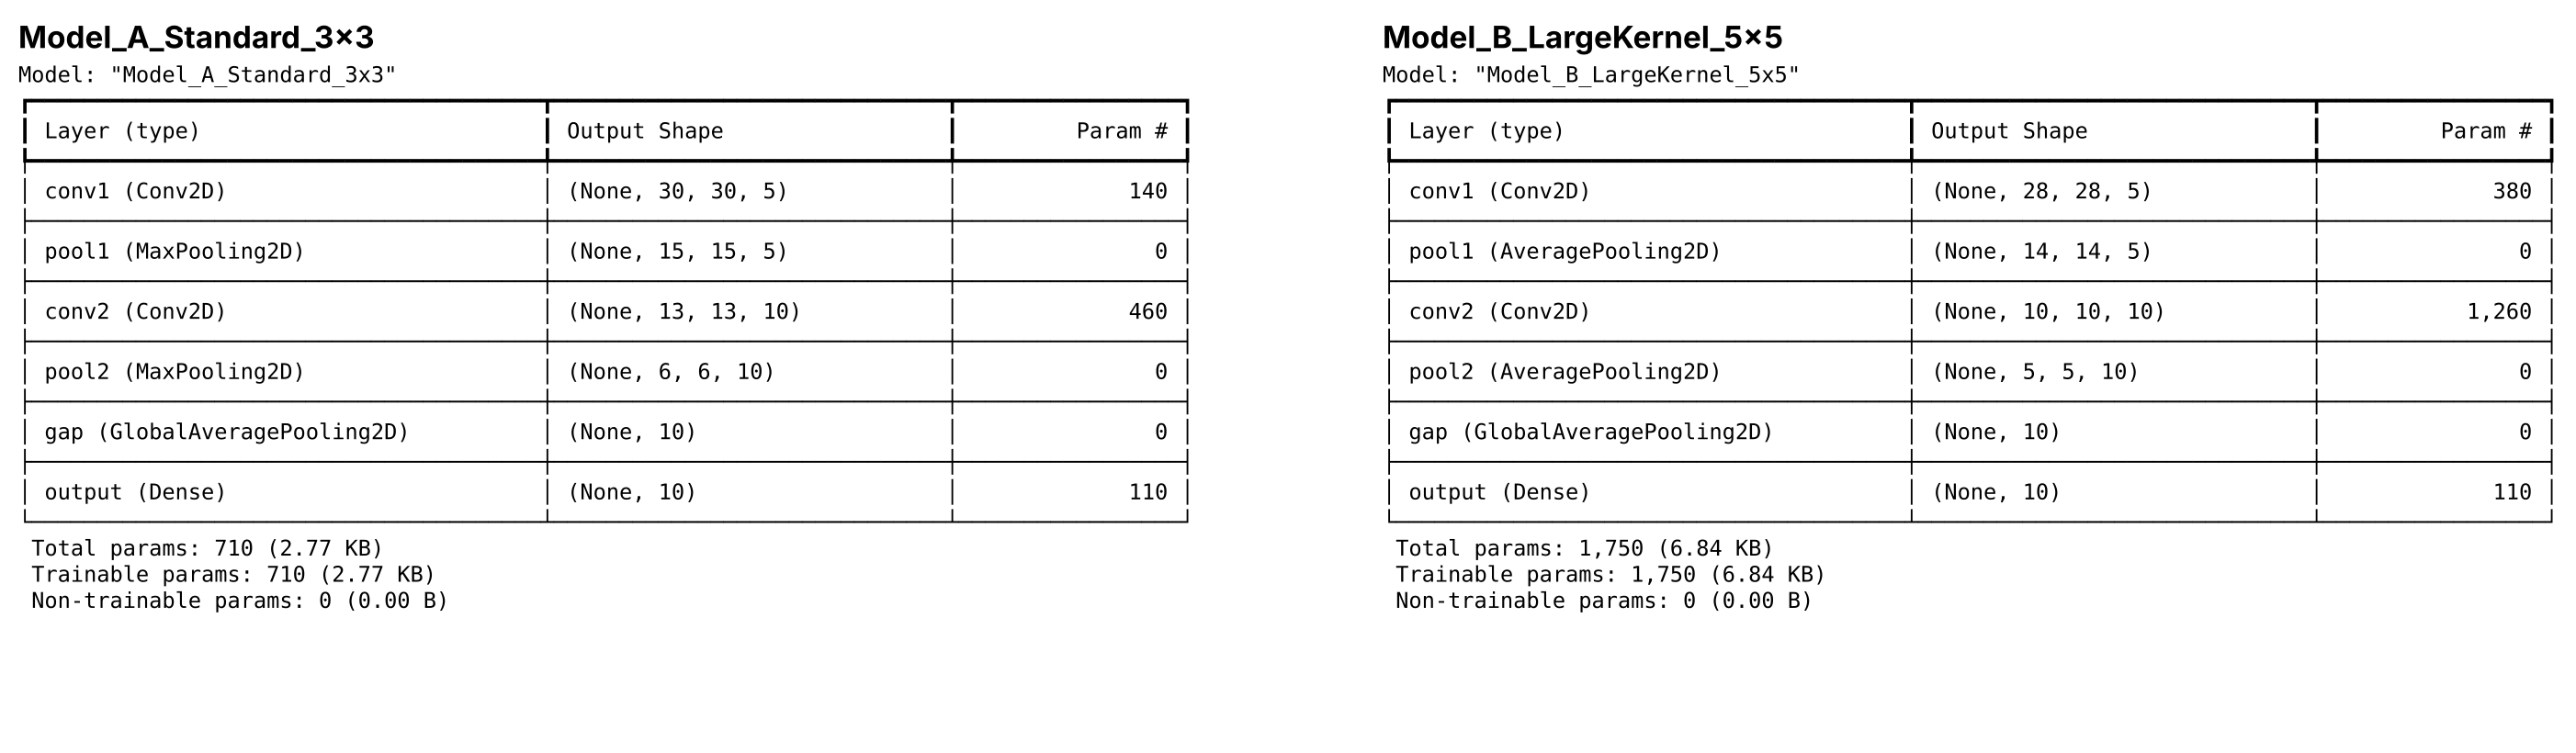

In [ ]:
import re
def strip_ansi(s): return re.sub(r"\x1b\[[0-9;]*m", "", s)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
for ax, (nm, txt) in zip(axes, summaries.items()):
    ax.axis("off")
    ax.text(0, 1, strip_ansi(txt), family="monospace", fontsize=8.5, va="top")
    ax.set_title(nm, fontsize=12, fontweight="bold", loc="left")
plt.tight_layout()
plt.savefig("part2_model_summaries.png", dpi=150, bbox_inches="tight")
plt.show()

## 2.3 Manual count vs code output (completed audit table)

In [ ]:
def layer_counts(m):
    return {l.name: l.count_params() for l in m.layers}

audit = []
for m, man, conv, ksz, pool in [(model_A, manual_A, "Conv1: 5 filters, Conv2: 10 filters", "3x3", "Max Pooling (2x2, stride 2)"),
                                (model_B, manual_B, "Conv1: 5 filters, Conv2: 10 filters", "5x5", "Avg Pooling (2x2, stride 2)")]:
    lc = layer_counts(m)
    code_total = m.count_params()
    trainable = int(sum(np.prod(w.shape) for w in m.trainable_weights))
    audit.append({"Model Configuration": m.name, "Conv Architecture": conv, "Kernel Size": ksz,
                  "Pooling Type": pool, "Manual Count": man["total"], "Code Output": trainable,
                  "Match": man["total"] == trainable == code_total,
                  "conv1 (man/code)": f'{man["conv1"]} / {lc["conv1"]}',
                  "conv2 (man/code)": f'{man["conv2"]} / {lc["conv2"]}',
                  "dense (man/code)": f'{man["dense"]} / {lc["output"]}'})
audit_df = pd.DataFrame(audit)
assert audit_df["Match"].all(), "manual count does not match Keras"
audit_df

,Model Configuration,Conv Architecture,Kernel Size,Pooling Type,Manual Count,Code Output,Match,conv1 (man/code),conv2 (man/code),dense (man/code)
0,Model_A_Standard_3x3,"Conv1: 5 filters, Conv2: 10 filters",3x3,"Max Pooling (2x2, stride 2)",710,710,True,140 / 140,460 / 460,110 / 110
1,Model_B_LargeKernel_5x5,"Conv1: 5 filters, Conv2: 10 filters",5x5,"Avg Pooling (2x2, stride 2)",1750,1750,True,380 / 380,1260 / 1260,110 / 110


## 2.4 Receptive field comparison

Receptive field (RF) of one output unit, computed layer by layer with
RF<sub>new</sub> = RF<sub>old</sub> + (k - 1) x jump, and jump<sub>new</sub> = jump<sub>old</sub> x stride.

In [ ]:
def receptive_field(layers_spec):
    rf, jump, out = 1, 1, []
    for name, k, s in layers_spec:
        rf = rf + (k - 1) * jump
        jump = jump * s
        out.append((name, k, s, rf, jump))
    return pd.DataFrame(out, columns=["Layer", "Kernel", "Stride", "RF (pixels)", "Jump"])

rfA = receptive_field([("conv1", 3, 1), ("pool1", 2, 2), ("conv2", 3, 1), ("pool2", 2, 2)])
rfB = receptive_field([("conv1", 5, 1), ("pool1", 2, 2), ("conv2", 5, 1), ("pool2", 2, 2)])
print("Model A"); display(rfA)
print("Model B"); display(rfB)

# feature map sizes
for m in (model_A, model_B):
    print(m.name, [ (l.name, tuple(l.output.shape[1:])) for l in m.layers ])

Model A


,Layer,Kernel,Stride,RF (pixels),Jump
0,conv1,3,1,3,1
1,pool1,2,2,4,2
2,conv2,3,1,8,2
3,pool2,2,2,10,4


Model B


,Layer,Kernel,Stride,RF (pixels),Jump
0,conv1,5,1,5,1
1,pool1,2,2,6,2
2,conv2,5,1,14,2
3,pool2,2,2,16,4


Model_A_Standard_3x3 [('conv1', (30, 30, 5)), ('pool1', (15, 15, 5)), ('conv2', (13, 13, 10)), ('pool2', (6, 6, 10)), ('gap', (10,)), ('output', (10,))]
Model_B_LargeKernel_5x5 [('conv1', (28, 28, 5)), ('pool1', (14, 14, 5)), ('conv2', (10, 10, 10)), ('pool2', (5, 5, 10)), ('gap', (10,)), ('output', (10,))]


# Supporting experiments for the Critical Thinking questions

## Q1 support: where does ReLU black out the edge maps?

Red marks pixels where Stage A was clearly negative (below -0.1) and ReLU set them to 0. Green marks pixels that were clearly positive and survived. Overlaid on the input image.

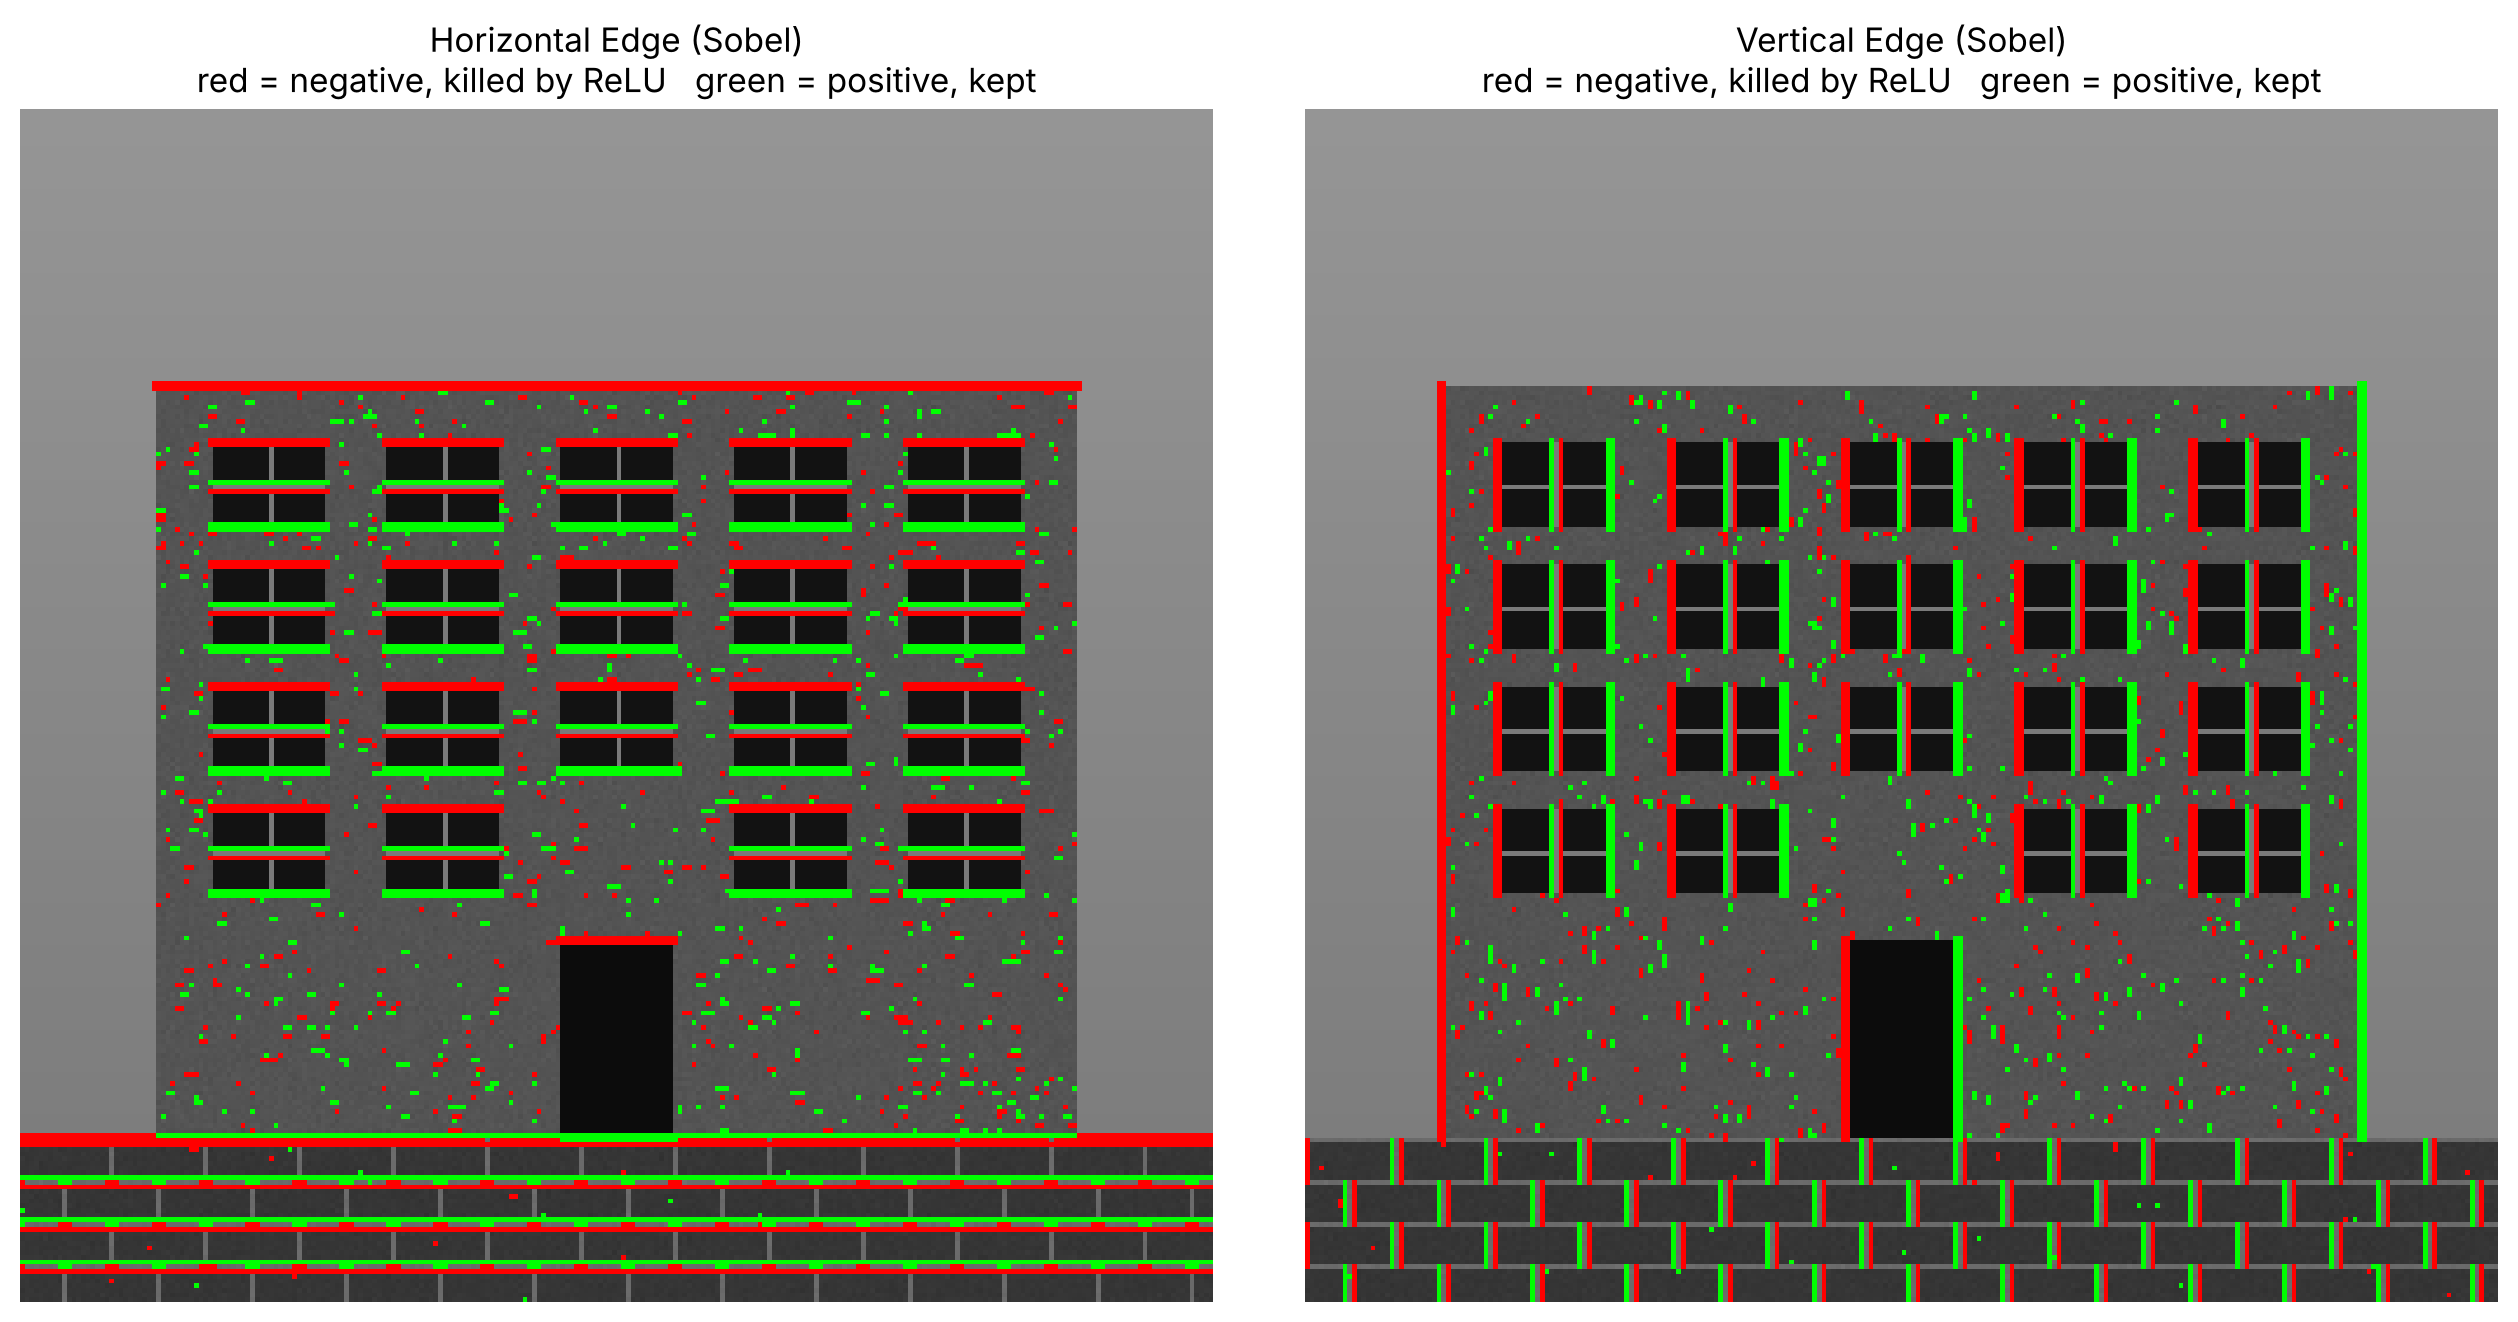

,Raw conv value (Stage A),After ReLU
"Horizontal kernel @ roof line (sky -> wall), y=59, x=100",-1.6086,0.0000
"Horizontal kernel @ window TOP edge (wall -> glass), y=72, x=48",-1.7126,0.0000
"Horizontal kernel @ window BOTTOM edge (glass -> wall), y=89, x=48",1.7649,1.7649
"Horizontal kernel @ sky gradient, y=30, x=10",-0.0058,0.0000
"Horizontal kernel @ door top (wall -> door), y=178, x=128",-1.9391,0.0000
"Horizontal kernel @ ground line (sky/wall -> brick), y=220, x=10",-1.8996,0.0000
"Vertical kernel @ window LEFT edge (wall -> glass), x=42, y=78",-1.7006,0.0000
"Vertical kernel @ window RIGHT edge (glass -> wall), x=65, y=78",1.7593,1.7593
"Vertical kernel @ left wall edge (sky -> wall), x=30, y=150",-1.3002,0.0000
"Vertical kernel @ right wall edge (wall -> sky), x=225, y=150",1.2565,1.2565


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
for ax, name in zip(axes, ["Horizontal Edge (Sobel)", "Vertical Edge (Sobel)"]):
    A = results[name]["A"]
    base = np.stack([img[1:-1, 1:-1]] * 3, -1) * 0.6
    base[A < -0.1] = [1, 0, 0]
    base[A > 0.1] = [0, 1, 0]
    ax.imshow(base); ax.set_title(f"{name}\nred = negative, killed by ReLU   green = positive, kept")
    ax.axis("off")
plt.tight_layout(); plt.savefig("q1_relu_blackout_map.png", dpi=130, bbox_inches="tight"); plt.show()

# measure responses at named structures (row/col in Stage A coordinates = image coord - 1)
H = results["Horizontal Edge (Sobel)"]["A"]; V = results["Vertical Edge (Sobel)"]["A"]
probes = {
    "Horizontal kernel @ roof line (sky -> wall), y=59, x=100": H[59 - 1, 100 - 1],
    "Horizontal kernel @ window TOP edge (wall -> glass), y=72, x=48": H[72 - 1, 48 - 1],
    "Horizontal kernel @ window BOTTOM edge (glass -> wall), y=89, x=48": H[89 - 1, 48 - 1],
    "Horizontal kernel @ sky gradient, y=30, x=10": H[30 - 1, 10 - 1],
    "Horizontal kernel @ door top (wall -> door), y=178, x=128": H[178 - 1, 128 - 1],
    "Horizontal kernel @ ground line (sky/wall -> brick), y=220, x=10": H[220 - 1, 10 - 1],
    "Vertical kernel @ window LEFT edge (wall -> glass), x=42, y=78": V[78 - 1, 42 - 1],
    "Vertical kernel @ window RIGHT edge (glass -> wall), x=65, y=78": V[78 - 1, 65 - 1],
    "Vertical kernel @ left wall edge (sky -> wall), x=30, y=150": V[150 - 1, 30 - 1],
    "Vertical kernel @ right wall edge (wall -> sky), x=225, y=150": V[150 - 1, 225 - 1],
}
probe_df = pd.DataFrame({"Raw conv value (Stage A)": probes}).assign(**{"After ReLU": lambda d: d.iloc[:, 0].clip(lower=0)})
probe_df

### Q1 support: ReLU vs Leaky ReLU (alpha = 0.1) vs Sigmoid on the same raw maps

Each activation panel uses its own colorbar. For Leaky ReLU the scale is symmetric so you can see that negative edges are still present, just 10 times weaker.

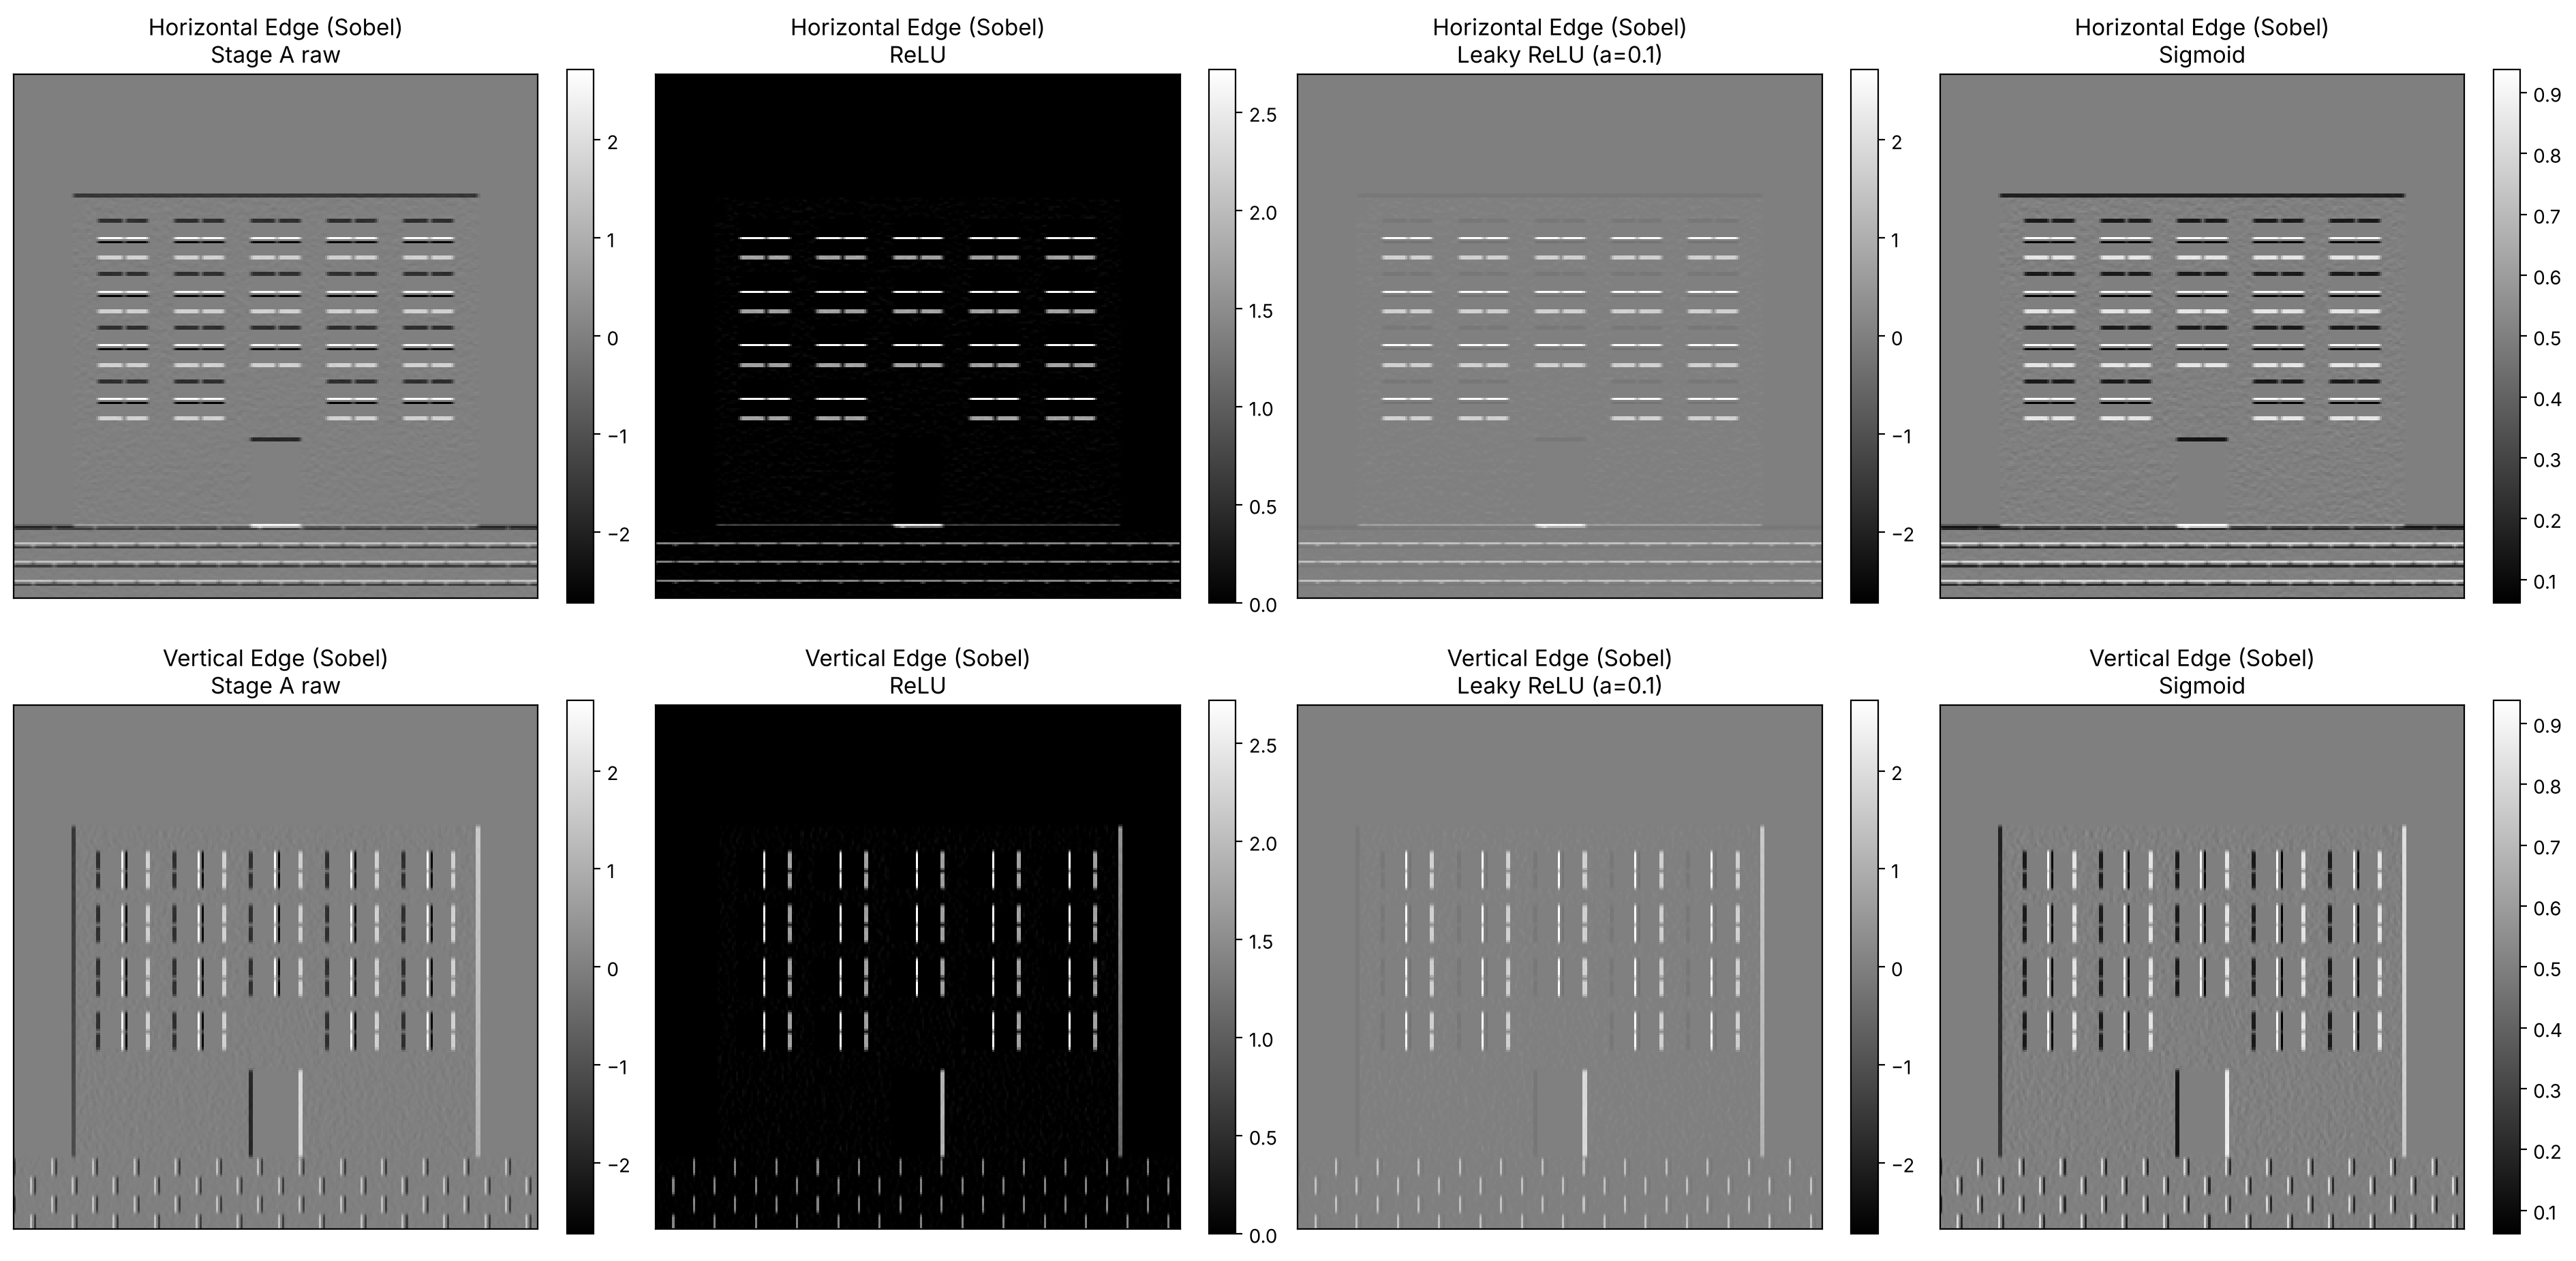

,Filter,Activation,Min,Max,Value where raw = 0,% pixels exactly 0,% pixels negative
0,Horizontal Edge (Sobel),ReLU,0.0000,2.7200,0.0,65.5651,0.0000
1,Horizontal Edge (Sobel),Leaky ReLU (a=0.1),-0.2720,2.7200,0.0,1.3640,64.2011
2,Horizontal Edge (Sobel),Sigmoid,0.0618,0.9382,0.5,0.0000,0.0000
3,Vertical Edge (Sobel),ReLU,0.0000,2.7200,0.0,73.8142,0.0000
4,Vertical Edge (Sobel),Leaky ReLU (a=0.1),-0.2720,2.7200,0.0,47.5107,26.3036
5,Vertical Edge (Sobel),Sigmoid,0.0618,0.9382,0.5,0.0000,0.0000


In [ ]:
acts = {
    "ReLU": tf.nn.relu,
    "Leaky ReLU (a=0.1)": lambda t: tf.nn.leaky_relu(t, alpha=0.1),
    "Sigmoid": tf.nn.sigmoid,
}
fig, axes = plt.subplots(2, 4, figsize=(19, 9.5))
act_rows = []
for i, name in enumerate(["Horizontal Edge (Sobel)", "Vertical Edge (Sobel)"]):
    A = results[name]["A"]; m = np.abs(A).max()
    im = axes[i, 0].imshow(A, cmap="gray", vmin=-m, vmax=m); axes[i, 0].set_title(f"{name}\nStage A raw")
    fig.colorbar(im, ax=axes[i, 0], fraction=0.046)
    for j, (an, fn) in enumerate(acts.items(), start=1):
        out = fn(tf.constant(A)).numpy()
        if an.startswith("Leaky"):
            mm = np.abs(out).max(); im = axes[i, j].imshow(out, cmap="gray", vmin=-mm, vmax=mm)
        else:
            im = axes[i, j].imshow(out, cmap="gray", vmin=out.min(), vmax=out.max())
        axes[i, j].set_title(f"{name}\n{an}"); fig.colorbar(im, ax=axes[i, j], fraction=0.046)
        act_rows.append({"Filter": name, "Activation": an, "Min": out.min(), "Max": out.max(),
                         "Value where raw = 0": float(fn(tf.constant(0.0)).numpy()),
                         "% pixels exactly 0": 100 * (out == 0).mean(),
                         "% pixels negative": 100 * (out < 0).mean()})
for ax in axes.ravel(): ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig("q1_activation_comparison.png", dpi=120, bbox_inches="tight"); plt.show()
pd.DataFrame(act_rows)

## Q2 support: Max Pooling vs Average Pooling

**(a) Zoom on one window** (top-left window, Stage B to D) for the Sharpen and edge rows. The mullions are 1 pixel wide in the input, which is the finest detail in the image.

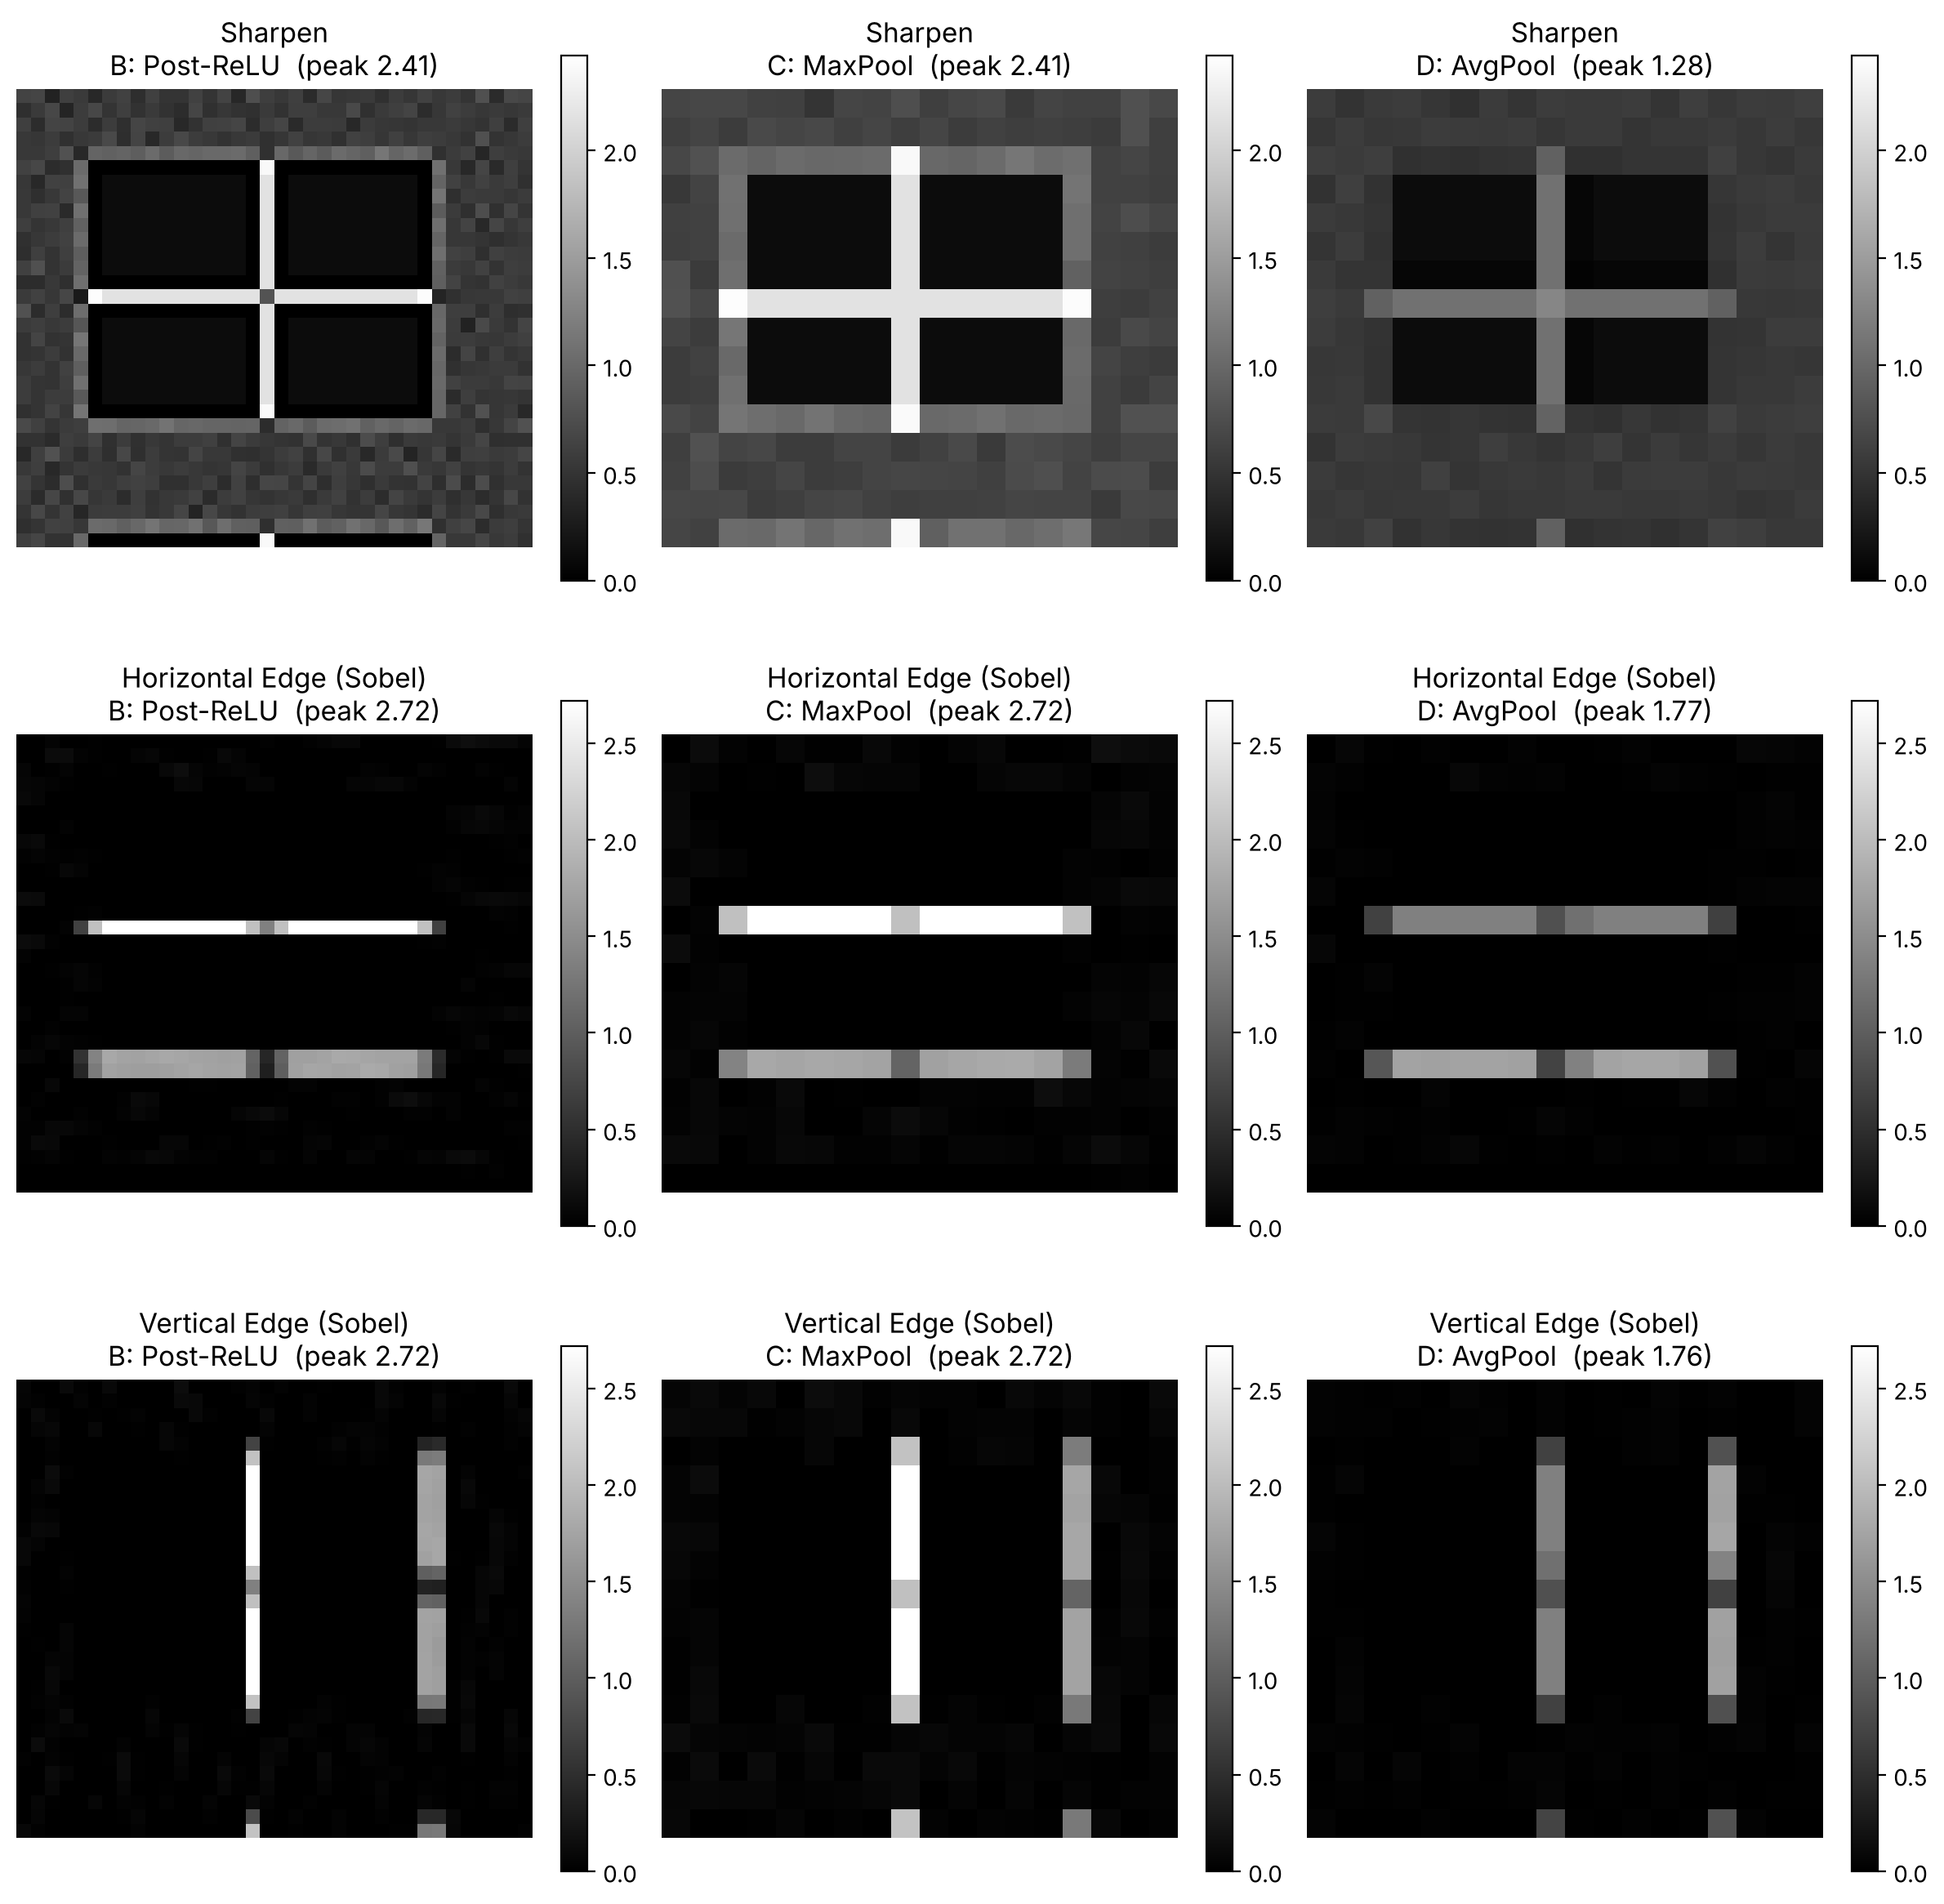

In [ ]:
y0, y1, x0, x1 = 66, 98, 36, 72     # Stage B coords around the first window
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for i, name in enumerate(["Sharpen", "Horizontal Edge (Sobel)", "Vertical Edge (Sobel)"]):
    st = results[name]; vmax = st["B"].max()
    crops = [st["B"][y0:y1, x0:x1], st["C"][y0//2:y1//2, x0//2:x1//2], st["D"][y0//2:y1//2, x0//2:x1//2]]
    for j, (c, t) in enumerate(zip(crops, ["B: Post-ReLU", "C: MaxPool", "D: AvgPool"])):
        im = axes[i, j].imshow(c, cmap="gray", vmin=0, vmax=vmax, interpolation="nearest")
        axes[i, j].set_title(f"{name}\n{t}  (peak {c.max():.2f})"); axes[i, j].axis("off")
        fig.colorbar(im, ax=axes[i, j], fraction=0.046)
plt.tight_layout(); plt.savefig("q2_window_zoom.png", dpi=120, bbox_inches="tight"); plt.show()

**(b) Numbers**: how much of the peak response and of the strong-edge energy survives each pooling type.

In [ ]:
def hf_energy(t):
    # mean squared Laplacian = amount of fine, high-frequency detail
    return float(np.mean(cv2.Laplacian(t.astype(np.float32), cv2.CV_32F) ** 2))

pool_rows = []
for name, st in results.items():
    B, C, D = st["B"], st["C"], st["D"]
    thr = 0.5 * B.max()
    pool_rows.append({"Filter": name,
                      "Peak B": B.max(), "Peak C (max)": C.max(), "Peak D (avg)": D.max(),
                      "Mean of top-1% B": np.sort(B.ravel())[-int(0.01 * B.size):].mean(),
                      "Mean of top-1% C": np.sort(C.ravel())[-int(0.01 * C.size):].mean(),
                      "Mean of top-1% D": np.sort(D.ravel())[-int(0.01 * D.size):].mean(),
                      "Strong px (>50% peak) in C": int((C > thr).sum()),
                      "Strong px (>50% peak) in D": int((D > thr).sum()),
                      "HF energy C": hf_energy(C), "HF energy D": hf_energy(D)})
pool_df = pd.DataFrame(pool_rows).set_index("Filter")
pool_df["HF ratio D/C"] = pool_df["HF energy D"] / pool_df["HF energy C"]
pool_df

,Peak B,Peak C (max),Peak D (avg),Mean of top-1% B,Mean of top-1% C,Mean of top-1% D,Strong px (>50% peak) in C,Strong px (>50% peak) in D,HF energy C,HF energy D,HF ratio D/C
Filter,,,,,,,,,,,
Horizontal Edge (Sobel),2.7200,2.7200,2.0591,2.3585,2.7200,1.7333,781,204,1.2599,0.4879,0.3872
Vertical Edge (Sobel),2.7200,2.7200,1.9308,2.1730,2.6043,1.5942,599,125,0.9722,0.3544,0.3646
Sharpen,2.4407,2.4407,1.2800,2.1892,2.2771,1.1098,1212,19,1.1288,0.2537,0.2247
Gaussian Blur,0.9793,0.9793,0.9789,0.9787,0.9790,0.9786,12076,11478,0.0228,0.0155,0.6786
Emboss,2.8400,2.8400,2.0865,2.1809,2.2423,1.7687,1124,482,1.0792,0.5960,0.5522


**(c) Intensity profile across one vertical mullion** (Sharpen, Stage B row through the first window, and the matching pooled row).

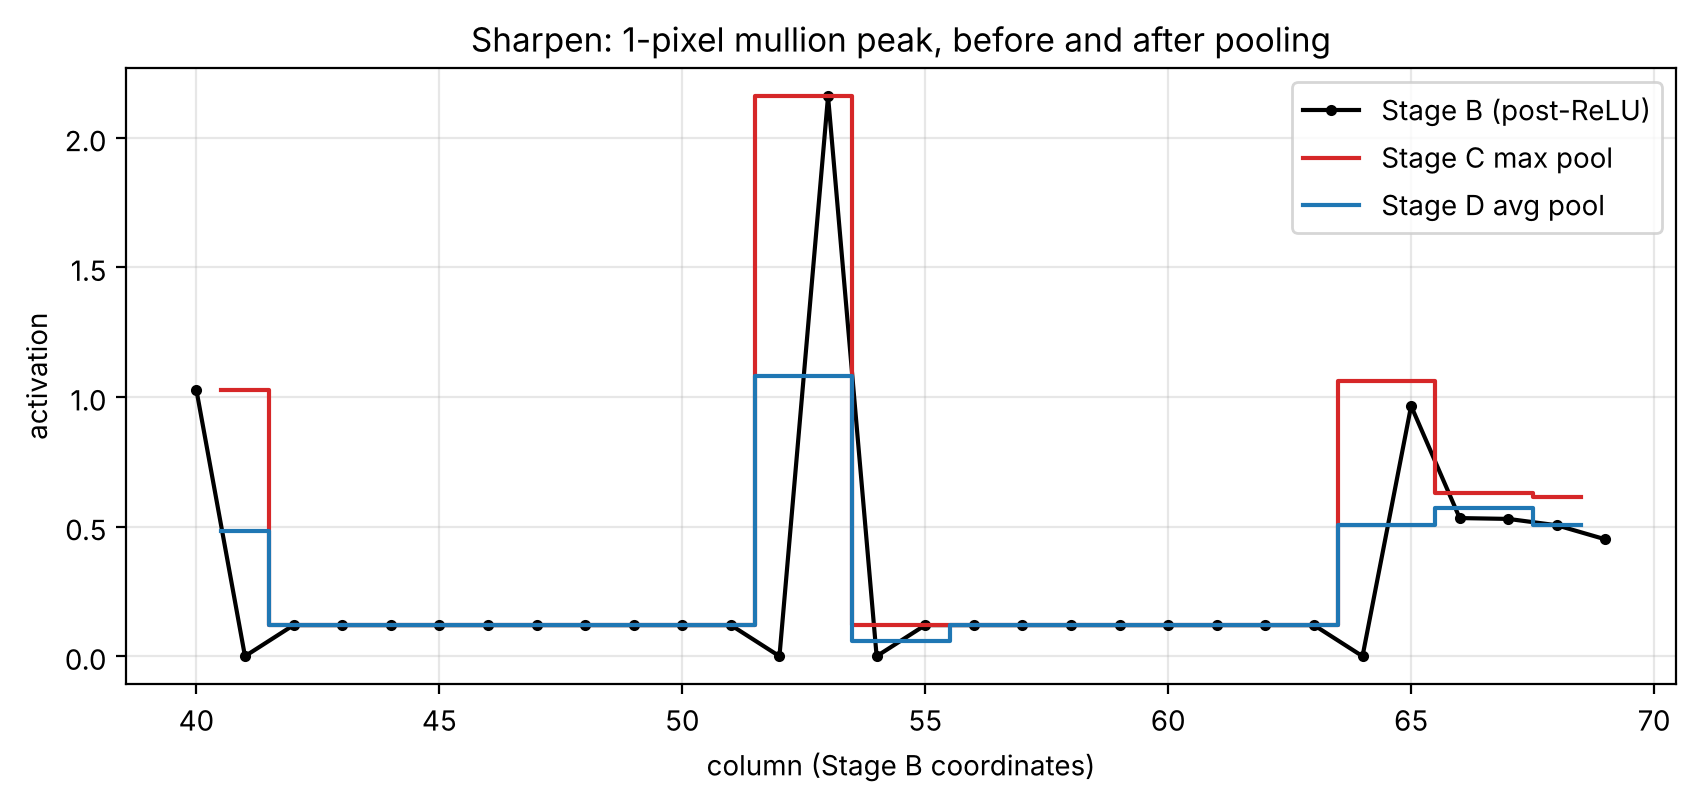

mullion peak  B = 2.16  C = 2.16  D = 1.08


In [ ]:
st = results["Sharpen"]
row_b = 76            # Stage B row inside first window (image row 77)
xs = np.arange(40, 70)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(xs, st["B"][row_b, xs], "k.-", label="Stage B (post-ReLU)")
xp = np.arange(20, 35)
ax.step(xp * 2 + 0.5, st["C"][row_b // 2, xp], where="mid", color="tab:red", label="Stage C max pool")
ax.step(xp * 2 + 0.5, st["D"][row_b // 2, xp], where="mid", color="tab:blue", label="Stage D avg pool")
ax.set_xlabel("column (Stage B coordinates)"); ax.set_ylabel("activation"); ax.legend(); ax.grid(alpha=.3)
ax.set_title("Sharpen: 1-pixel mullion peak, before and after pooling")
plt.savefig("q2_mullion_profile.png", dpi=120, bbox_inches="tight"); plt.show()
print("mullion peak  B =", st["B"][row_b, 53], " C =", st["C"][row_b // 2, 26], " D =", st["D"][row_b // 2, 26])

**(d) Dark ink text on a white background.** Pooling is applied directly to the image (pixel values 0 to 255, background = 255, ink near 0). Min pooling and "invert, then max pool" are added for comparison because they are the usual fixes.

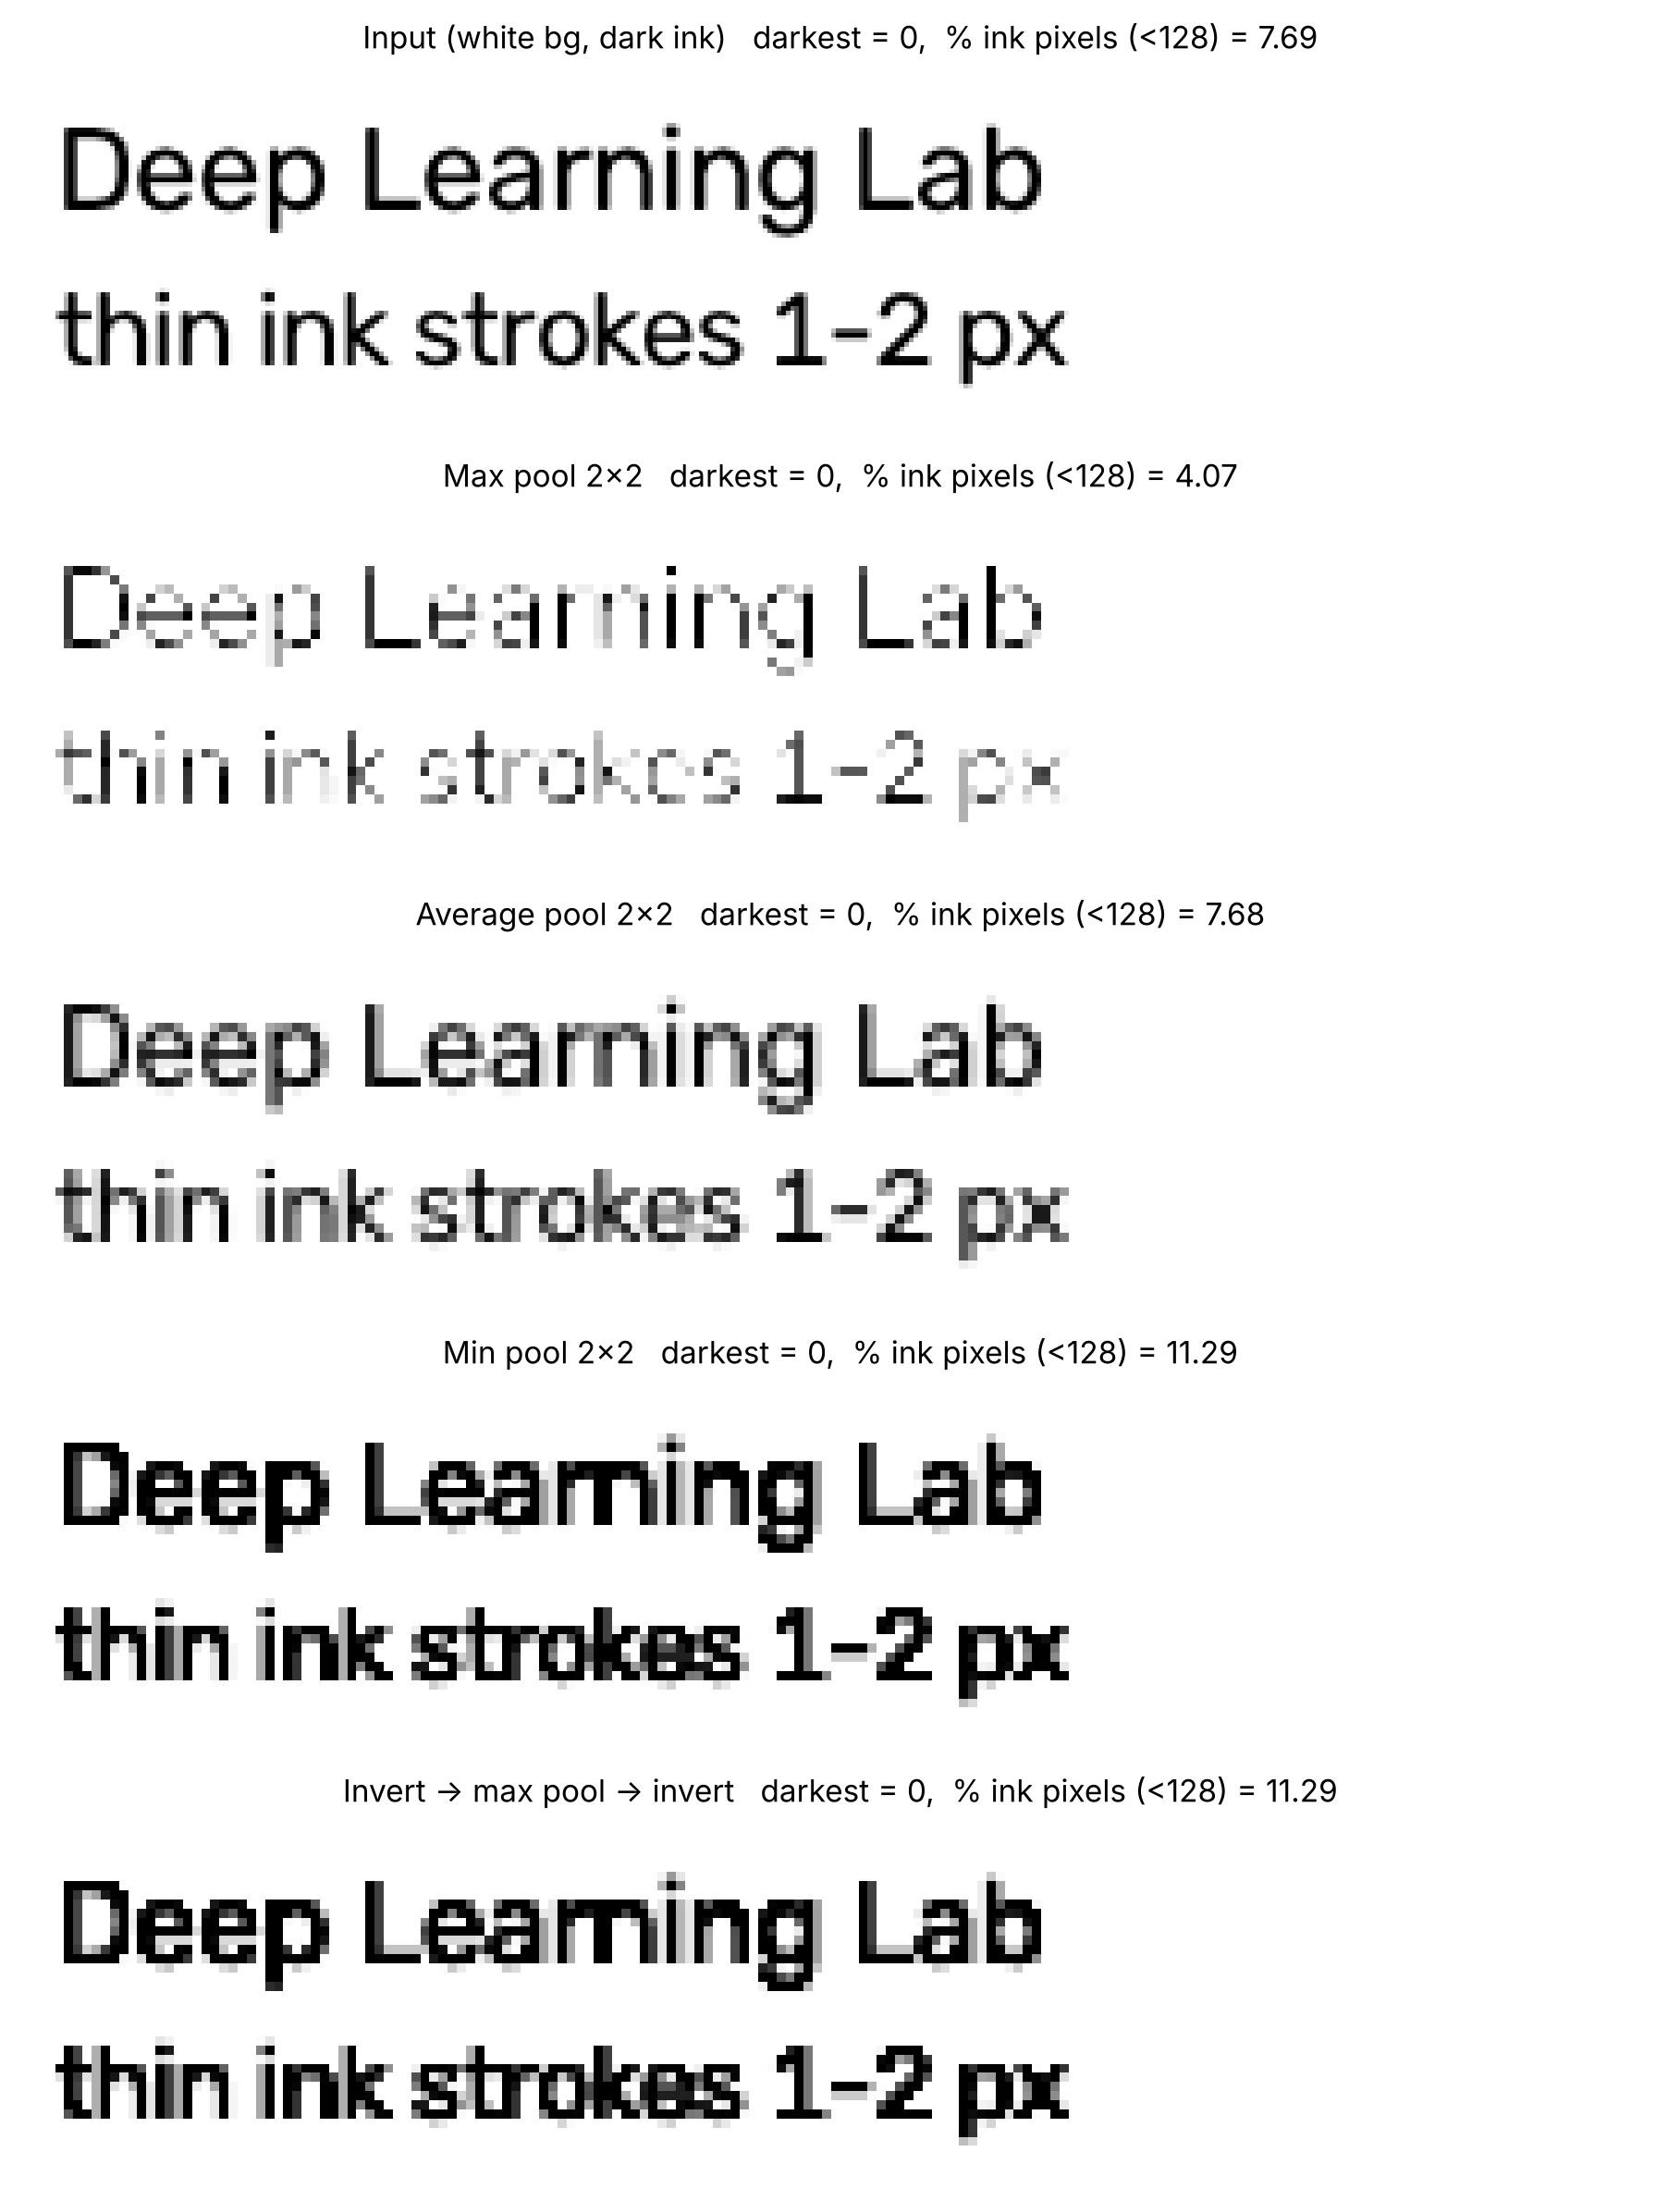

,Operation,Darkest value,% ink pixels (<128),Mean value
0,"Input (white bg, dark ink)",0.0,7.6875,235.2961
1,Max pool 2x2,0.0,4.0694,244.7318
2,Average pool 2x2,0.0,7.6806,235.2961
3,Min pool 2x2,0.0,11.2917,225.6544
4,Invert -> max pool -> invert,0.0,11.2917,225.6544


In [ ]:
doc = np.full((80, 360), 255, np.uint8)
cv2.putText(doc, "Deep Learning Lab", (8, 32), cv2.FONT_HERSHEY_SIMPLEX, 0.9, 0, 1, cv2.LINE_AA)
cv2.putText(doc, "thin ink strokes 1-2 px", (8, 66), cv2.FONT_HERSHEY_PLAIN, 1.4, 0, 1, cv2.LINE_AA)
t = tf.constant(doc.astype(np.float32)[None, :, :, None])
mp = tf.nn.max_pool2d(t, 2, 2, "VALID").numpy()[0, :, :, 0]
ap = tf.nn.avg_pool2d(t, 2, 2, "VALID").numpy()[0, :, :, 0]
mnp = -tf.nn.max_pool2d(-t, 2, 2, "VALID").numpy()[0, :, :, 0]
inv = 255 - tf.nn.max_pool2d(255 - t, 2, 2, "VALID").numpy()[0, :, :, 0]

ink_in = (doc < 128).mean() * 100
panels = [("Input (white bg, dark ink)", doc), ("Max pool 2x2", mp), ("Average pool 2x2", ap),
          ("Min pool 2x2", mnp), ("Invert -> max pool -> invert", inv)]
fig, axes = plt.subplots(len(panels), 1, figsize=(10, 12))
txt_rows = []
for ax, (t_, p) in zip(axes, panels):
    ax.imshow(p, cmap="gray", vmin=0, vmax=255, interpolation="nearest"); ax.axis("off")
    ink = (p < 128).mean() * 100
    ax.set_title(f"{t_}   darkest = {p.min():.0f},  % ink pixels (<128) = {ink:.2f}")
    txt_rows.append({"Operation": t_, "Darkest value": p.min(), "% ink pixels (<128)": ink,
                     "Mean value": p.mean()})
plt.tight_layout(); plt.savefig("q2_text_pooling.png", dpi=120, bbox_inches="tight"); plt.show()
pd.DataFrame(txt_rows)

## Q3 support: parameter increase and stacked 3x3 layers

In [ ]:
tA, tB = manual_A["total"], manual_B["total"]
print(f"Total params   A = {tA},  B = {tB}")
print(f"Increase A -> B = ({tB} - {tA}) / {tA} x 100 = {100 * (tB - tA) / tA:.2f} %")
cA = manual_A["conv1"] + manual_A["conv2"]; cB = manual_B["conv1"] + manual_B["conv2"]
print(f"Conv layers only: A = {cA}, B = {cB}, increase = {100 * (cB - cA) / cA:.2f} %")
print(f"Weights only (no bias): 25/9 = {25/9:.3f}  ->  +{100*(25/9-1):.2f} % per conv layer")

Total params   A = 710,  B = 1750
Increase A -> B = (1750 - 710) / 710 x 100 = 146.48 %
Conv layers only: A = 600, B = 1640, increase = 173.33 %
Weights only (no bias): 25/9 = 2.778  ->  +177.78 % per conv layer


In [ ]:
# Same receptive field: one 5x5 vs two stacked 3x3 (stride 1). Check with Keras for several channel settings.
def count(layers_list, cin):
    m = keras.Sequential([keras.Input((32, 32, cin))] + layers_list)
    return m.count_params()

cases = []
for cin, cmid, cout, label in [(3, 5, 5, "Conv1 of our models (3 -> 5), middle layer 5"),
                               (5, 5, 10, "Conv2 of our models (5 -> 10), middle layer 5"),
                               (5, 10, 10, "Conv2 (5 -> 10), middle layer 10"),
                               (64, 64, 64, "Typical block, C = 64 -> 64 -> 64")]:
    one = count([layers.Conv2D(cout, 5)], cin)
    two = count([layers.Conv2D(cmid, 3), layers.Conv2D(cout, 3)], cin)
    cases.append({"Case": label, "One 5x5": one, "Two 3x3": two, "Saved": one - two,
                  "% saved": 100 * (one - two) / one})
pd.DataFrame(cases)

,Case,One 5x5,Two 3x3,Saved,% saved
0,"Conv1 of our models (3 -> 5), middle layer 5",380,370,10,2.6316
1,"Conv2 of our models (5 -> 10), middle layer 5",1260,690,570,45.2381
2,"Conv2 (5 -> 10), middle layer 10",1260,1370,-110,-8.7302
3,"Typical block, C = 64 -> 64 -> 64",102464,73856,28608,27.9200


one 5x5 layer    -> footprint (np.int64(5), np.int64(5))
two 3x3 layers   -> footprint (np.int64(5), np.int64(5))
three 3x3 layers -> footprint (np.int64(7), np.int64(7))


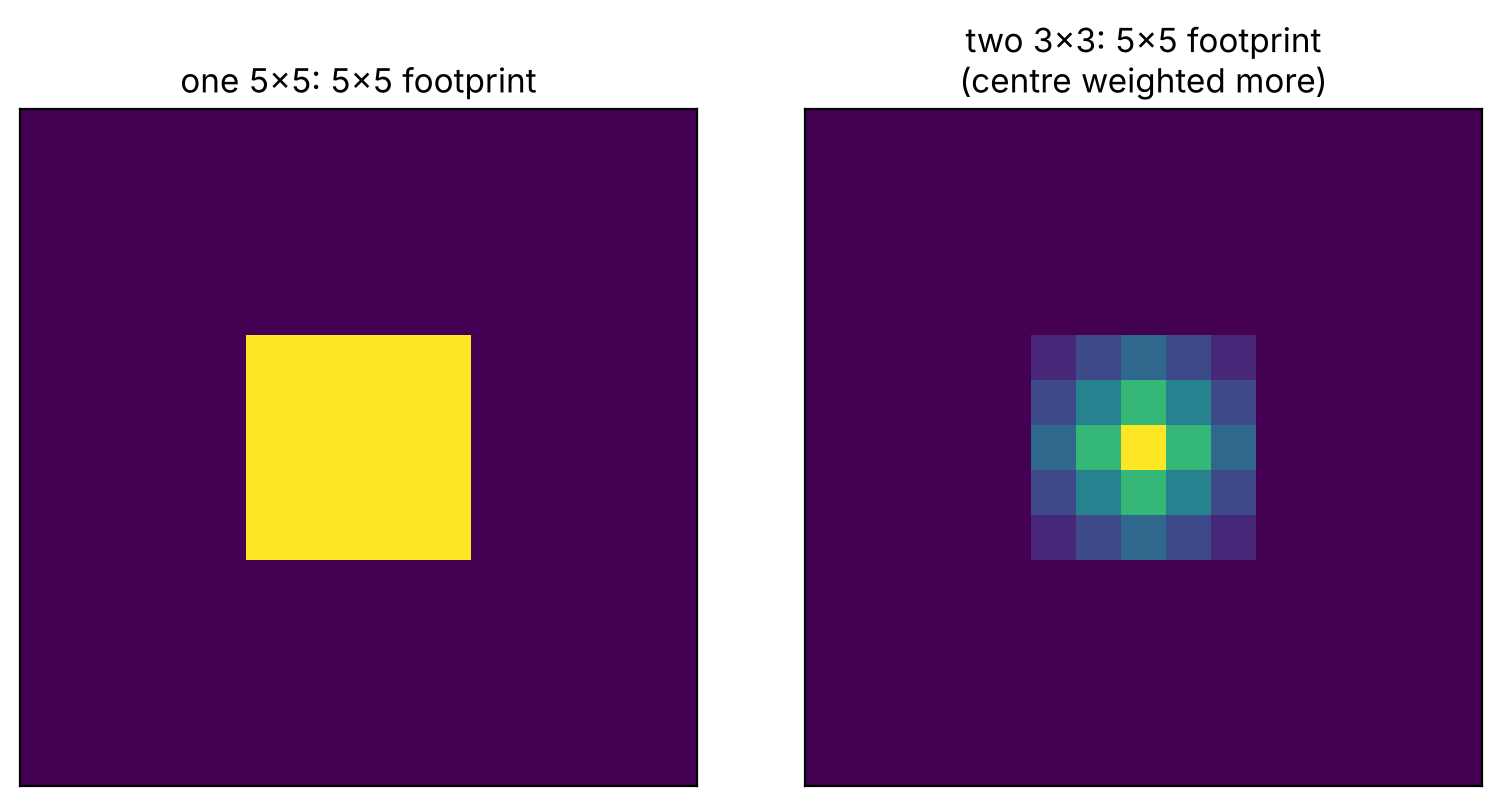

In [ ]:
# Prove the receptive field empirically: put a single 1 in the middle of a 15x15 image,
# pass it through all-ones kernels, and see how far the output spreads.
imp = np.zeros((1, 15, 15, 1), np.float32); imp[0, 7, 7, 0] = 1
ones3 = tf.ones((3, 3, 1, 1)); ones5 = tf.ones((5, 5, 1, 1))
one5 = tf.nn.conv2d(imp, ones5, 1, "SAME").numpy()[0, :, :, 0]
two3 = tf.nn.conv2d(tf.nn.conv2d(imp, ones3, 1, "SAME"), ones3, 1, "SAME").numpy()[0, :, :, 0]
def span(a):
    r, c = np.nonzero(a); return (r.max() - r.min() + 1, c.max() - c.min() + 1)
print("one 5x5 layer    -> footprint", span(one5))
print("two 3x3 layers   -> footprint", span(two3))
print("three 3x3 layers -> footprint", span(tf.nn.conv2d(tf.constant(two3[None,:,:,None]), ones3, 1, "SAME").numpy()[0,:,:,0]))
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(one5, cmap="viridis"); ax[0].set_title("one 5x5: 5x5 footprint")
ax[1].imshow(two3, cmap="viridis"); ax[1].set_title("two 3x3: 5x5 footprint\n(centre weighted more)")
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig("q3_receptive_field.png", dpi=120, bbox_inches="tight"); plt.show()

## Q4 support: Conv -> ReLU -> MaxPool vs Conv -> MaxPool -> ReLU

In [ ]:
def relu(a): return np.maximum(a, 0)

patches = {
    "all negative": np.array([[-3., -1.], [-2., -5.]]),
    "mixed":        np.array([[-4.,  2.], [ 1., -3.]]),
}
for nm, p in patches.items():
    path1 = relu(p).max()          # ReLU then MaxPool
    path2 = relu(p.max())          # MaxPool then ReLU
    print(f"{nm:13s} patch {p.tolist()}:  ReLU->Max = {path1},  Max->ReLU = {path2}")

# check on every full feature map from Part I
print()
for name, st in results.items():
    A = tf.constant(st["A"][None, :, :, None])
    p1 = tf.nn.max_pool2d(tf.nn.relu(A), 2, 2, "VALID")
    p2 = tf.nn.relu(tf.nn.max_pool2d(A, 2, 2, "VALID"))
    q1 = tf.nn.avg_pool2d(tf.nn.relu(A), 2, 2, "VALID")
    q2 = tf.nn.relu(tf.nn.avg_pool2d(A, 2, 2, "VALID"))
    print(f"{name:25s} max-pool order identical: {np.array_equal(p1.numpy(), p2.numpy())}"
          f"   |  avg-pool order identical: {np.allclose(q1.numpy(), q2.numpy())}"
          f" (max diff {np.abs(q1.numpy() - q2.numpy()).max():.3f})")

all negative  patch [[-3.0, -1.0], [-2.0, -5.0]]:  ReLU->Max = 0.0,  Max->ReLU = 0.0
mixed         patch [[-4.0, 2.0], [1.0, -3.0]]:  ReLU->Max = 2.0,  Max->ReLU = 2.0

Horizontal Edge (Sobel)   max-pool order identical: True   |  avg-pool order identical: False (max diff 0.350)
Vertical Edge (Sobel)     max-pool order identical: True   |  avg-pool order identical: False (max diff 0.066)
Sharpen                   max-pool order identical: True   |  avg-pool order identical: False (max diff 0.450)
Gaussian Blur             max-pool order identical: True   |  avg-pool order identical: True (max diff 0.000)
Emboss                    max-pool order identical: True   |  avg-pool order identical: False (max diff 0.562)


In [ ]:
# Cost of each order on a realistic layer size: 64 channels, 224x224
big = tf.random.normal((8, 224, 224, 64))
def t(fn, n=20):
    fn(); s = time.perf_counter()
    for _ in range(n): fn()
    return (time.perf_counter() - s) / n * 1000
t1 = t(lambda: tf.nn.max_pool2d(tf.nn.relu(big), 2, 2, "VALID"))
t2 = t(lambda: tf.nn.relu(tf.nn.max_pool2d(big, 2, 2, "VALID")))
n = 224 * 224 * 64 * 8
print(f"ReLU calls  Conv->ReLU->Pool: {n:,}   Conv->Pool->ReLU: {n//4:,}  (4x fewer)")
print(f"time  Conv->ReLU->Pool: {t1:.2f} ms   Conv->Pool->ReLU: {t2:.2f} ms")

ReLU calls  Conv->ReLU->Pool: 25,690,112   Conv->Pool->ReLU: 6,422,528  (4x fewer)
time  Conv->ReLU->Pool: 14.87 ms   Conv->Pool->ReLU: 6.43 ms


## Q5 support: reproducing filter collapse

A small synthetic 4-class dataset (horizontal stripes, vertical stripes, diagonal stripes, blobs), 32x32x3, so the experiment runs offline. The same CNN layout as Model A (5 filters in Layer 1) is trained for 20 epochs under four settings. After training, the 5 Layer-1 filters are compared by pairwise cosine similarity (1.0 means identical), and the number of dead filters (output is zero for every training image) is counted.

In [ ]:
def make_dataset(n=2000, seed=0):
    rng = np.random.default_rng(seed)
    X = np.zeros((n, 32, 32, 3), np.float32); y = rng.integers(0, 4, n)
    yy, xx = np.mgrid[0:32, 0:32]
    for i in range(n):
        f = rng.uniform(0.25, 0.6); ph = rng.uniform(0, 6.28)
        if y[i] == 0: base = np.sin(f * yy + ph)
        elif y[i] == 1: base = np.sin(f * xx + ph)
        elif y[i] == 2: base = np.sin(f * (xx + yy) / 1.4 + ph)
        else:
            base = np.zeros((32, 32))
            for _ in range(3):
                cy, cx, r = rng.uniform(4, 28, 2).tolist() + [rng.uniform(3, 7)]
                base += np.exp(-((yy - cy) ** 2 + (xx - cx) ** 2) / (2 * r * r))
            base = base * 2 - 1
        col = rng.uniform(0.5, 1.0, 3)
        X[i] = (0.5 + 0.4 * base[..., None] * col) + rng.normal(0, 0.05, (32, 32, 3))
    return np.clip(X, 0, 1), y

Xtr, ytr = make_dataset(2000, 0); Xte, yte = make_dataset(500, 1)

def make_net(init, act="relu", bn=False):
    L = [keras.Input((32, 32, 3)), layers.Conv2D(5, 3, kernel_initializer=init, name="conv1")]
    if bn: L.append(layers.BatchNormalization())
    L += [layers.Activation(act) if isinstance(act, str) else act,
          layers.MaxPooling2D(2),
          layers.Conv2D(10, 3, activation="relu"), layers.MaxPooling2D(2),
          layers.GlobalAveragePooling2D(), layers.Dense(4, activation="softmax")]
    return keras.Sequential(L)

def filter_report(model, X):
    W = model.get_layer("conv1").get_weights()[0].reshape(-1, 5).T     # (5, 27)
    Wn = W / (np.linalg.norm(W, axis=1, keepdims=True) + 1e-12)
    S = Wn @ Wn.T
    off = S[~np.eye(5, dtype=bool)]
    # feature map after the activation that follows conv1
    idx = [i for i, l in enumerate(model.layers) if isinstance(l, (layers.Activation, layers.LeakyReLU))][0]
    fmap = keras.Model(model.inputs, model.layers[idx].output).predict(X, verbose=0)
    dead = int(((fmap <= 0).all(axis=(0, 1, 2))).sum())
    return float(np.abs(off).mean()), float(np.abs(off).min()), dead, fmap

configs = {
    "1) Constant init (all filters = 0.05), Adam lr=1e-3":
        dict(init=keras.initializers.Constant(0.05), opt=lambda: keras.optimizers.Adam(1e-3)),
    "2) Fix for 1: He-normal init, Adam lr=1e-3":
        dict(init="he_normal", opt=lambda: keras.optimizers.Adam(1e-3)),
    "3) He init, SGD lr=3.0 (learning rate far too high)":
        dict(init="he_normal", opt=lambda: keras.optimizers.SGD(3.0)),
    "4) Fix for 3: lr=0.05 + BatchNorm + LeakyReLU(0.1)":
        dict(init="he_normal", opt=lambda: keras.optimizers.SGD(0.05, momentum=0.9),
             act=layers.LeakyReLU(negative_slope=0.1), bn=True),
}
q5_rows, q5_maps = [], {}
for name, c in configs.items():
    tf.random.set_seed(SEED); np.random.seed(SEED)
    net = make_net(c["init"], c.get("act", "relu"), c.get("bn", False))
    net.compile(c["opt"](), "sparse_categorical_crossentropy", metrics=["accuracy"])
    h = net.fit(Xtr, ytr, epochs=20, batch_size=64, verbose=0, validation_data=(Xte, yte))
    mean_sim, min_sim, dead, fmap = filter_report(net, Xtr[:256])
    q5_maps[name] = fmap[0]
    q5_rows.append({"Setting": name, "Mean |cos sim| between filters": mean_sim,
                    "Min |cos sim|": min_sim, "Dead filters (of 5)": dead,
                    "Final train acc": h.history["accuracy"][-1], "Final test acc": h.history["val_accuracy"][-1],
                    "Final loss": h.history["loss"][-1]})
q5_df = pd.DataFrame(q5_rows)
q5_df

,Setting,Mean |cos sim| between filters,Min |cos sim|,Dead filters (of 5),Final train acc,Final test acc,Final loss
0,"1) Constant init (all filters = 0.05), Adam lr...",0.9900,0.9676,0,0.9280,0.938,0.2444
1,"2) Fix for 1: He-normal init, Adam lr=1e-3",0.1916,0.0683,0,0.9790,0.982,0.1754
2,"3) He init, SGD lr=3.0 (learning rate far too ...",0.1390,0.0082,2,0.2405,0.260,1.4120
3,4) Fix for 3: lr=0.05 + BatchNorm + LeakyReLU(...,0.2675,0.0133,0,1.0000,0.998,0.0017


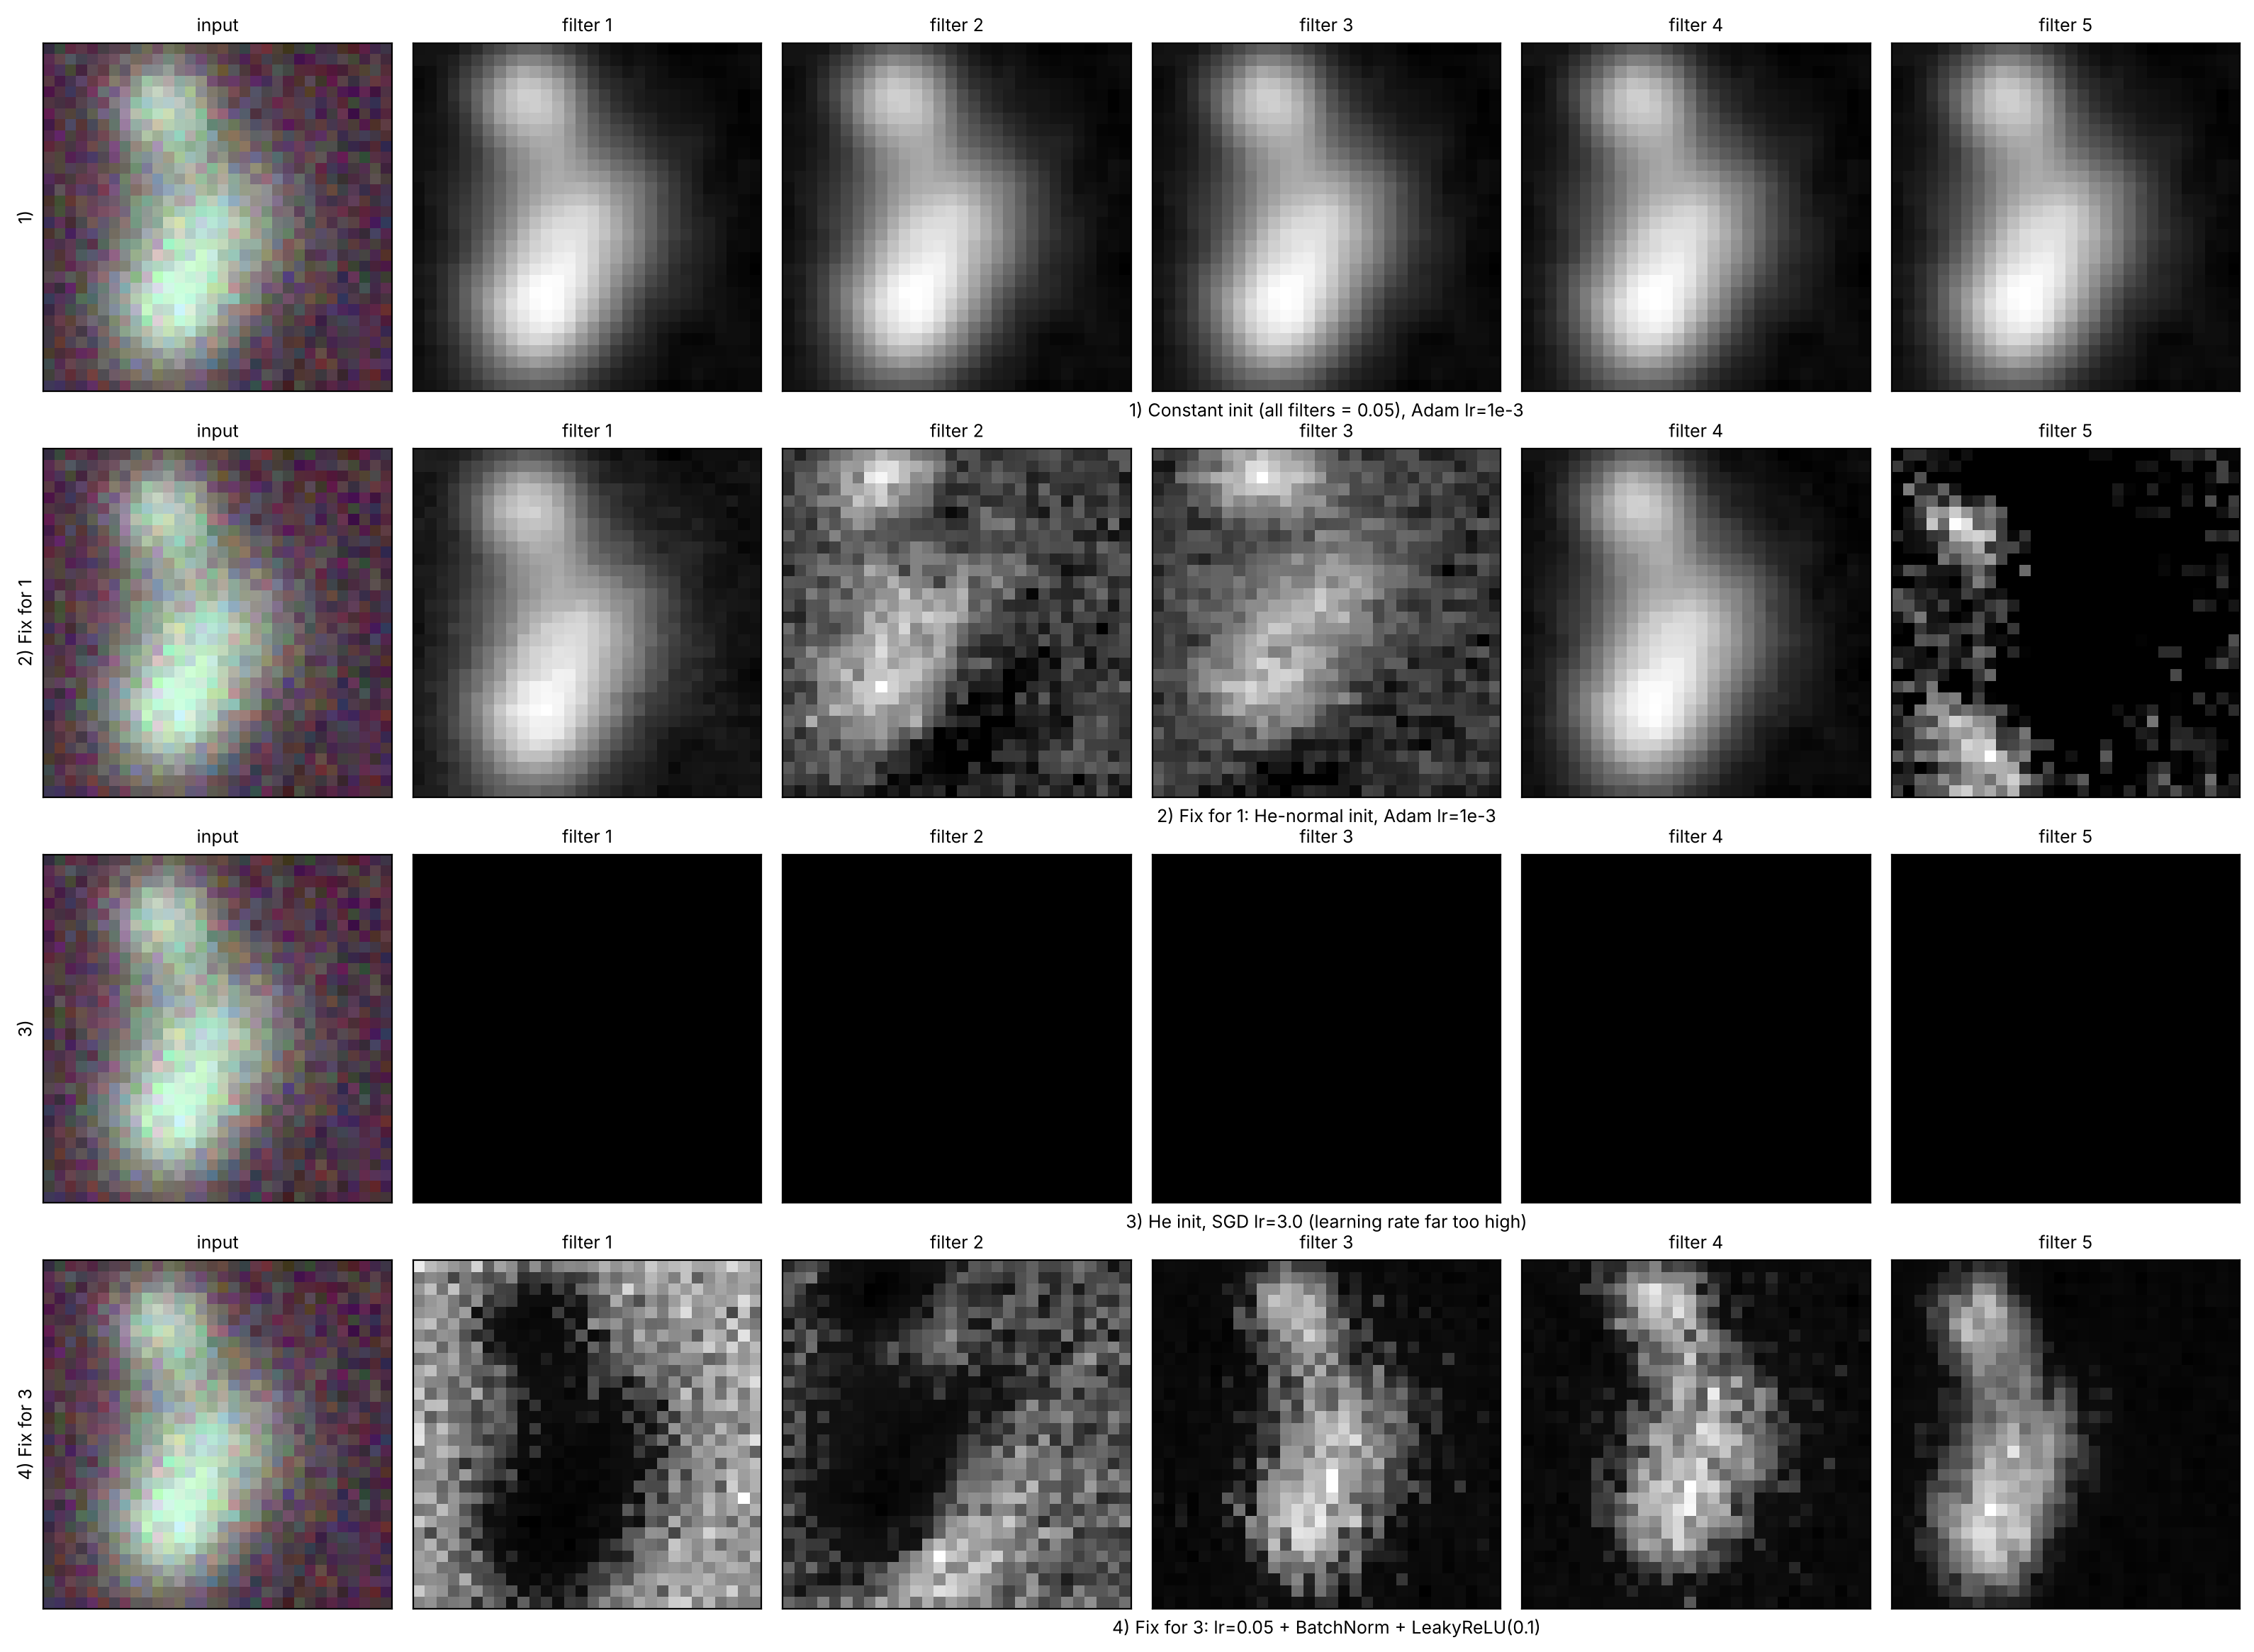

1) max activation of each filter on the sample image: [ 8.494 10.288  8.008  9.431  9.477]
2) max activation of each filter on the sample image: [ 6.614  0.895  1.114 11.214  0.453]
3) max activation of each filter on the sample image: [0. 0. 0. 0. 0.]
4) max activation of each filter on the sample image: [4.298 4.142 5.133 4.09  7.07 ]


In [ ]:
fig, axes = plt.subplots(len(q5_maps), 6, figsize=(16, 2.9 * len(q5_maps)))
for i, (name, fm) in enumerate(q5_maps.items()):
    axes[i, 0].imshow(Xtr[0]); axes[i, 0].set_title("input", fontsize=9)
    for k in range(5):
        axes[i, k + 1].imshow(fm[:, :, k], cmap="gray"); axes[i, k + 1].set_title(f"filter {k+1}", fontsize=9)
    axes[i, 0].set_ylabel(name.split(":")[0] if ":" in name else name[:2], fontsize=9)
    axes[i, 3].set_xlabel(name, fontsize=9)
for a in axes.ravel(): a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig("q5_filter_collapse.png", dpi=110, bbox_inches="tight"); plt.show()
for name, fm in q5_maps.items():
    print(f"{name[:2]} max activation of each filter on the sample image:", np.round(fm.reshape(-1, 5).max(0), 3))